# Projeto AVD · Diabetes e reinternação hospitalar

Este notebook contém a Parte Específica do projeto. A análise parte de uma pergunta: o histórico de internações e de idas à emergência no ano anterior ajuda a identificar quais pacientes diabéticos voltam ao hospital em menos de 30 dias? Para responder, usamos a base pública *Diabetes 130-US Hospitals* (101.766 internações entre 1999 e 2008).

**Como executar:** abra no Google Colab, faça login e use **Ambiente de execução → Executar tudo**, numa sessão CPU comum. Os dados e o código já estão dentro do notebook: não é preciso enviar CSV, montar o Drive nem configurar túnel. O painel interativo abre na última célula.

**Ordem das seções:** estrutura dos dados → qualidade e ausências → outliers → distribuições → relações e cruzamentos → resposta à pergunta (storytelling) → catálogo → dashboard.

A Parte Comum (K-Means) é entregue separadamente. O relatório PDF gerado aqui usa a base inteira; no painel é possível filtrar outros recortes.

O uso de IA neste trabalho está descrito na **Declaração de uso de IA**, no fim do notebook.

(Os trechos de código feitos com IA estão marcados com `# [IA] Claude`. Os textos analíticos redigidos com IA estão em `src/parte_especifica/textos_grupo.py`. Veja a Declaração de uso de IA no fim do notebook.)

In [1]:
# @title 1 · Instalar dependências
import subprocess
import sys

if sys.version_info < (3, 11):
    raise RuntimeError("Este projeto requer Python 3.11 ou superior.")
packages = [
    "streamlit==1.67.0", "pandas==2.2.3", "numpy==2.3.5",
    "plotly==6.9.0", "scikit-learn==1.8.0", "matplotlib==3.10.8", "reportlab==4.4.9",
    "seaborn==0.13.2",  # [IA] Claude – dependência dos novos heatmaps
]
print("Instalando as dependências. A primeira execução pode levar alguns minutos...")
subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *packages])
print("Dependências instaladas.")


Instalando as dependências. A primeira execução pode levar alguns minutos...


Dependências instaladas.


In [1]:
# @title 2 · Preparar projeto e dados incorporados
from pathlib import Path
import base64
import hashlib
import io
import os
import zipfile

PROJECT = Path(os.environ.get("AVD_PROJECT_DIR", "/content/projeto-avd" if Path("/content").is_dir() else "projeto-avd-colab")).resolve()
PROJECT.mkdir(parents=True, exist_ok=True)
# [IA] Claude – pacote atualizado com os módulos alterados e o módulo textos_grupo.py (textos do grupo)
PAYLOAD_B64 = (
    "..."
)
package = base64.b64decode(PAYLOAD_B64, validate=True)
assert hashlib.sha256(package).hexdigest() == "916de37068a9326510388edfef196688db3f03a90f305aadcc2abf3a1e846627", "Pacote incompleto: reenvie o notebook original."
with zipfile.ZipFile(io.BytesIO(package)) as z:
    for entry in z.infolist():
        target = (PROJECT / entry.filename).resolve()
        if not target.is_relative_to(PROJECT):
            raise ValueError("O pacote contém um caminho inválido.")
    z.extractall(PROJECT)
del PAYLOAD_B64, package
print("Projeto e dados preparados em:", PROJECT)
print("Arquivos: dashboard.py, diabetic_data.csv, IDS_mapping.csv, requirements.txt e explicacao.md.")


Projeto e dados preparados em: /home/claude/work/runproj
Arquivos: dashboard.py, diabetic_data.csv, IDS_mapping.csv, requirements.txt e explicacao.md.


## 3. Preparação, pergunta e arquivos da análise

**Pergunta do grupo:** Quanto mais vezes o paciente foi internado no ano anterior, e quanto mais vezes foi à emergência, maior a chance de voltar ao hospital em menos de 30 dias? Isso vale para cada um separadamente e para os dois combinados? E o padrão se mantém quando olhamos só os pacientes que foram reinternados em algum momento?

Para responder, dividimos a pergunta em três partes, cada uma ligada a um gráfico:

1. **Cada histórico separadamente:** Quanto maior o número de internações no ano anterior (0, 1, 2, 3 ou mais), maior a taxa de reinternação em menos de 30 dias? E quanto maior o número de idas à emergência? → *X1 e X2*
2. **Os dois históricos combinados:** Quando o paciente tem as duas coisas ao mesmo tempo, internações e emergências, o risco é ainda maior? → *M2*
3. **Só quem voltou ao hospital:** Esses padrões se mantêm quando olhamos apenas os pacientes que foram reinternados em algum momento (sem as linhas NO)? → *C1*

**Público:** gestores de qualidade hospitalar e analistas de dados que precisam decidir quais pacientes acompanhar depois da alta.

**Como lemos a base:** cada linha é uma internação, e não um paciente. O alvo é binário: `readmitted == '<30'` (voltou em menos de 30 dias) contra todo o resto. O "resto" junta quem voltou depois de 30 dias (`>30`) e quem não tem reinternação registrada (`NO`), como no artigo original. Na seção 8, repetimos a análise sem as linhas `NO`.

A célula abaixo roda toda a análise a partir dos dados originais e gera de novo as tabelas, as figuras, o relatório PDF, o relatório Markdown e o arquivo de explicações.

In [2]:
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown
sys.path.insert(0, str(PROJECT / "src/parte_especifica"))
from analise import run_analysis, chart_notes, NUMERIC, LABELS, AGE_ORDER
from figuras import create_figures
from documentos import create_documents, story_text
# [IA] Claude – imports das novas tabelas
from analise import TEXTO_GRUPO, PARES_AUSENCIA, format_pct, audit_positive
import textos_grupo as TG  # textos escritos pelo grupo
# [IA] Claude – base principal com as linhas readmitted == "NO" mantidas
# False = mantém "NO" (base principal: <30 dias contra todo o resto).
# A base sem "NO" (somente reinternados) aparece como comparação na seção 8.
REMOVER_NO = False
raw, dados, tabelas, resumo = run_analysis(PROJECT, remover_no=REMOVER_NO)
figuras = create_figures(raw, dados, tabelas, PROJECT)
catalogo = create_documents(raw, dados, tabelas, resumo, figuras, PROJECT)
notas = chart_notes(dados)
print(json.dumps(resumo, ensure_ascii=False, indent=2))
print("Linhas na base usada:", len(raw))
print("Relatório gerado: out/parte_especifica/relatorio_parte_especifica.pdf")
print("Explicações geradas: explicacao.md")
def exibir_nota(chave):
    nota = notas[chave]
    display(Markdown("**O que mostra:** " + nota["o_que_mostra"] + "\n\n**Interpretação:** " + nota["interpretacao"] + "\n\n**Escolha visual:** " + nota["escolha_visual"]))


{
  "remover_no": false,
  "n_internacoes": 101766,
  "n_pacientes": 71518,
  "n_atributos": 50,
  "casos_30": 11357,
  "taxa_30_pct": 11.159915885462727,
  "duplicatas_completas": 0,
  "duplicatas_encounter_id": 0,
  "ocorrencias_extremas_por_atributo": 45358,
  "n_verificacoes": 54,
  "source_sha256": "0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97"
}
Linhas na base usada: 101766
Relatório gerado: relatorio.pdf
Explicações geradas: explicacao.md


## 4. Estrutura e tipos dos 50 atributos

Antes de calcular qualquer coisa, classificamos cada coluna pelo que ela significa, e não pelo tipo em que está gravada no CSV. Os códigos de admissão e de alta são números, mas representam categorias nominais. Idade e peso vêm em faixas ordenadas. Os diagnósticos são códigos textuais do ICD-9. Os dois identificadores (`encounter_id` e `patient_nbr`) servem para reconhecer registros e pacientes, e por isso ficam fora das medidas e das correlações.

As tabelas abaixo separam os atributos qualitativos dos quantitativos. Em seguida vêm as estatísticas das oito variáveis numéricas, com os comentários de assimetria e curtose.

In [3]:
# [IA] Claude – estrutura com descrição completa, dividida em qualitativos e quantitativos
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
    display(Markdown("#### Atributos qualitativos"))
    display(tabelas["estrutura_qualitativos"])
    display(Markdown("#### Atributos quantitativos"))
    display(tabelas["estrutura_quantitativos"])
    # [IA] Claude – identificadores separados das tabelas de atributos
    display(Markdown("#### Identificadores (não entram como atributos)"))
    display(tabelas["estrutura_identificadores"])
# [IA] Claude – estatísticas das variáveis numéricas
display(Markdown("#### Estatísticas das variáveis numéricas"))
display(tabelas["estatisticas_numericas"].round(3))

#### Atributos qualitativos

,atributo,dtype_python,tipo_semantico,papel,descricao,valores_distintos,ausentes_interrogacao,ausentes_pct,exemplos
0,race,str,Categórica nominal,Atributo,Categoria demográfica registrada na fonte.,5,2273,2.2336,Caucasian | AfricanAmerican | Other | Asian
1,gender,str,Categórica nominal,Atributo,Sexo registrado; Unknown/Invalid é categoria sem informação válida.,3,0,0.0000,Female | Male | Unknown/Invalid
2,age,str,Categórica ordinal em intervalos,Atributo,Faixa etária ordinal de dez anos.,10,0,0.0000,[0-10) | [10-20) | [20-30) | [30-40)
3,weight,str,Categórica ordinal em intervalos,Atributo,Faixa de peso em kg (limites convertidos de libras e arredondados); não é um peso pontual.,9,98569,96.8585,[34-45) | [23-34) | [0-11) | [45-57)
4,admission_type_id,int64,Categórica nominal,Atributo,Código nominal do tipo de admissão.,8,0,0.0000,6 | 1 | 2 | 3
5,discharge_disposition_id,int64,Categórica nominal,Atributo,Código nominal do destino na alta.,26,0,0.0000,25 | 1 | 3 | 6
6,admission_source_id,int64,Categórica nominal,Atributo,Código nominal da origem da admissão.,17,0,0.0000,1 | 7 | 2 | 4
7,payer_code,object,Categórica nominal,Atributo,Categoria de pagador registrada.,17,40256,39.5574,MC | MD | HM | UN
8,medical_specialty,str,Categórica nominal,Atributo,Especialidade médica registrada.,72,49949,49.0822,Pediatrics-Endocrinology | InternalMedicine | Family/GeneralPractice | Cardiology
9,diag_1,object,Categórica nominal,Atributo,Código textual do diagnóstico principal (ICD-9-CM).,716,21,0.0206,250.83 | 276 | 648 | 8


#### Atributos quantitativos

,atributo,dtype_python,tipo_semantico,papel,descricao,valores_distintos,ausentes_interrogacao,ausentes_pct,exemplos
0,time_in_hospital,int64,Quantitativa discreta,Atributo,Permanência (dias),14,0,0.0,1 | 3 | 2 | 4
1,num_lab_procedures,int64,Quantitativa discreta,Atributo,Exames laboratoriais,118,0,0.0,41 | 59 | 11 | 44
2,num_procedures,int64,Quantitativa discreta,Atributo,Procedimentos,7,0,0.0,0 | 5 | 1 | 6
3,num_medications,int64,Quantitativa discreta,Atributo,Medicamentos,75,0,0.0,1 | 18 | 13 | 16
4,number_outpatient,int64,Quantitativa discreta,Atributo,Consultas ambulatoriais prévias,39,0,0.0,0 | 2 | 1 | 5
5,number_emergency,int64,Quantitativa discreta,Atributo,Emergências prévias,33,0,0.0,0 | 1 | 2 | 4
6,number_inpatient,int64,Quantitativa discreta,Atributo,Internações prévias,21,0,0.0,0 | 1 | 2 | 3
7,number_diagnoses,int64,Quantitativa discreta,Atributo,Diagnósticos,16,0,0.0,1 | 9 | 6 | 7


#### Identificadores (não entram como atributos)

,atributo,dtype_python,tipo_semantico,papel,descricao,valores_distintos,ausentes_interrogacao,ausentes_pct,exemplos
0,encounter_id,int64,Identificador,ID,Identificador da internação; não é medida quantitativa.,101766,0,0.0,2278392 | 149190 | 64410 | 500364
1,patient_nbr,int64,Identificador,ID,Identificador do paciente; permite reconhecer registros repetidos.,71518,0,0.0,8222157 | 55629189 | 86047875 | 82442376


#### Estatísticas das variáveis numéricas

,atributo,mean,median,std,min,max,skewness,kurtosis
0,time_in_hospital,4.396,4.0,2.985,1.0,14.0,1.134,0.850
1,num_lab_procedures,43.096,44.0,19.674,1.0,132.0,-0.237,-0.245
2,num_procedures,1.340,1.0,1.706,0.0,6.0,1.316,0.857
3,num_medications,16.022,15.0,8.128,1.0,81.0,1.327,3.468
4,number_outpatient,0.369,0.0,1.267,0.0,42.0,8.833,147.908
5,number_emergency,0.198,0.0,0.930,0.0,76.0,22.856,1191.687
6,number_inpatient,0.636,0.0,1.263,0.0,21.0,3.614,20.719
7,number_diagnoses,7.423,8.0,1.934,1.0,16.0,-0.877,-0.079


#### Assimetria (skewness) e curtose (kurtosis)

- **Emergências prévias** (skewness 22,86 e kurtosis 1.191,7): a distribuição mais extrema da base. 88,8% das internações têm zero emergências, e poucos pacientes chegam a dezenas (máximo de 76). A média (0,20) não representa o paciente típico.
- **Consultas ambulatoriais prévias** (skewness 8,83 e kurtosis 147,9): mesmo padrão: 83,6% de zeros e uma cauda longa à direita (máximo de 42).
- **Internações prévias** (skewness 3,61 e kurtosis 20,7): assimetria forte, mas menor. 66,5% não tiveram internação no ano anterior, e a cauda chega a 21. É a variável central da pergunta, por isso foi agrupada em 0, 1, 2 e 3 ou mais.
- **Medicamentos** (skewness 1,33 e kurtosis 3,47): assimetria moderada à direita, com mediana de 15 e alguns casos acima de 35.
- **Permanência e procedimentos** (skewness 1,13 e 1,32; kurtosis 0,85 e 0,86): assimetria moderada e caudas leves. Os valores são limitados pelo próprio domínio (1 a 14 dias e 0 a 6 procedimentos).
- **Exames laboratoriais** (skewness -0,24 e kurtosis -0,25): quase simétrica, com média (43,1) e mediana (44) próximas.
- **Diagnósticos** (skewness -0,88 e kurtosis -0,08): assimetria à esquerda: os valores se acumulam no teto de 9 diagnósticos (48,6% das internações), e só 0,1% passa disso.

A kurtosis apresentada é o excesso de curtose (o valor da normal é 0). Nas três contagens de histórico, a média é puxada pela cauda, então descrevemos essas variáveis por mediana, percentis e grupos. Os coeficientes de Spearman foram mantidos ao lado dos de Pearson porque não dependem da forma da distribuição.

## 5. Qualidade: inconsistências, ausências e decisões

Nesta seção verificamos se a base é confiável. A auditoria procura linhas duplicadas, `encounter_id` repetido, valores fora do domínio, códigos sem correspondência no dicionário e diagnósticos com formato incomum. Várias internações do mesmo paciente **não** são duplicatas e foram mantidas. Códigos de diagnóstico com formato fora do padrão são apenas sinalizados.

A base tem quatro tipos de falta de informação, e cada um recebeu tratamento próprio:
- `?`: o dado não foi registrado;
- `Unknown/Invalid`: sexo sem valor válido;
- códigos administrativos que significam "sem informação";
- `None` em HbA1c e glicose: o exame **não foi feito**. Isso é uma informação, então o `None` continua como categoria.

A auditoria não encontrou linhas inteiramente duplicadas nem encounter_id repetido: cada linha é uma internação única. Há 30.248 linhas de pacientes que já aparecem em outra internação (71.518 pacientes para 101.766 internações). Isso não é erro, é a própria estrutura da base, e por isso essas linhas foram mantidas. A repetição de pacientes é avaliada na análise de sensibilidade da seção 8. Os domínios numéricos estão dentro do esperado (permanência entre 1 e 14 dias, contagens inteiras e não negativas). Os códigos de diagnóstico com formato fora do padrão ICD-9 (2.646 em diag_1, 1.560 em diag_2 e 1.526 em diag_3) são códigos de 1 ou 2 dígitos, como "38" e "8", que parecem ter perdido o zero à esquerda ("038" é septicemia). Eles foram apenas sinalizados: o formato sozinho não permite afirmar que o diagnóstico esteja errado.

In [4]:
# [IA] Claude – auditoria apenas com ocorrências > 0 e sem a coluna marcador
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(audit_positive(tabelas["auditoria_inconsistencias"]))
# [IA] Claude – contagem de ausentes e duplicatas, trocando "?" por np.nan antes de isna()
import numpy as np
df = raw.replace("?", np.nan)
faltantes = df.isna().sum()
display(faltantes[faltantes > 0].rename("df.isna().sum()").to_frame())
print("df.duplicated().sum():", df.duplicated().sum())
# [IA] Claude – tabela de ausências sem hipótese/tratamento/marcador e com percentual formatado
display(format_pct(tabelas["mecanismos_ausencia"].drop(columns="marcador")))

,verificacao,ocorrencias,tipo
0,Registros adicionais de pacientes já presentes,30248,Estrutura
1,Formato ICD-9 não usual: diag_1,2646,Verificação
2,Formato ICD-9 não usual: diag_2,1560,Verificação
3,Formato ICD-9 não usual: diag_3,1526,Verificação
4,Sexo Unknown/Invalid,3,Categoria sem informação


,df.isna().sum()
race,2273
weight,98569
payer_code,40256
medical_specialty,49949
diag_1,21
diag_2,358
diag_3,1423


df.duplicated().sum(): 0


,atributo,tipo,n,percentual
0,race,Marcador ?,2273,2.23%
1,weight,Marcador ?,98569,96.86%
2,payer_code,Marcador ?,40256,39.56%
3,medical_specialty,Marcador ?,49949,49.08%
4,diag_1,Marcador ?,21,0.02%
5,diag_2,Marcador ?,358,0.35%
6,diag_3,Marcador ?,1423,1.40%
7,gender,Unknown/Invalid,3,0.00%
8,admission_type_id,Código sem informação,10396,10.22%
9,discharge_disposition_id,Código sem informação,4680,4.60%


#### Hipóteses de ausência e tratamento

- **weight (96,9%):** Hipótese: o peso não era coletado de forma rotineira no sistema de origem. A falta depende do processo de registro, e não do paciente. A proporção de ausentes é quase igual nos três desfechos (95,8% a 97,6%) e em todas as faixas etárias, por isso a ausência pouco informa sobre a reinternação. Decisão: não imputar e não usar o peso como medida, porque restam só 3.197 registros com valor.
- **medical_specialty (49,1%):** Hipótese: ausência dependente de outras variáveis (MAR). A falta cresce com a idade (17,4% de 0 a 10 anos e 52,3% de 80 a 90) e é um pouco menor entre quem não foi reinternado (47,3%, contra 50,9% em <30). Provavelmente reflete o tipo de admissão e a rotina de cada hospital. Decisão: manter as linhas e usar "Não informado" como categoria explícita, para não perder metade da base.
- **payer_code (39,6%):** Hipótese: MAR ligado à idade e ao tipo de cobertura. A falta é de 91,3% entre 0 e 10 anos e cai para 28,4% acima de 90 anos, o que é coerente com a cobertura pública dos mais velhos (Medicare, código MC, é o pagador mais frequente da base). Quase não varia entre os desfechos (38,9% a 40,7%). Decisão: manter como "Não informado".
- **race (2,2%):** Hipótese: falha de registro no cadastro. A falta é um pouco maior entre quem não foi reinternado (2,8%, contra 1,7% em <30). Como o volume é pequeno, a categoria "Não informado" foi mantida.
- **diag_1, diag_2 e diag_3 (0,02% a 1,4%):** Hipótese: ausência estrutural. O diagnóstico secundário ou adicional falta quando o paciente teve menos diagnósticos registrados. O mapa de calor mostra que, das 358 internações sem diag_2, 279 também não têm diag_3. Decisão: manter e tratar como "Não informado", sem inventar diagnóstico.
- **A1Cresult (83,3%) e max_glu_serum (94,7%) = None:** Não é ausência: o exame não foi feito, e isso tem significado clínico (é a pergunta do artigo original). Decisão: manter None como categoria própria.
- **Ausências conjuntas:** Os mapas de calor mostram que as ausências não se concentram nas mesmas internações. Sem payer_code, 40,6% não têm especialidade, e com payer_code, 54,6% não têm. Isso afasta a ideia de um "bloco" de registros incompletos, que poderia ser excluído de uma só vez.

Os dados permitem verificar só se a falta muda com variáveis observadas (idade e desfecho). Não é possível provar MCAR, MAR ou MNAR, por isso as classificações acima são hipóteses. Em todos os casos, a decisão foi preservar as linhas, para não mudar a composição da base.

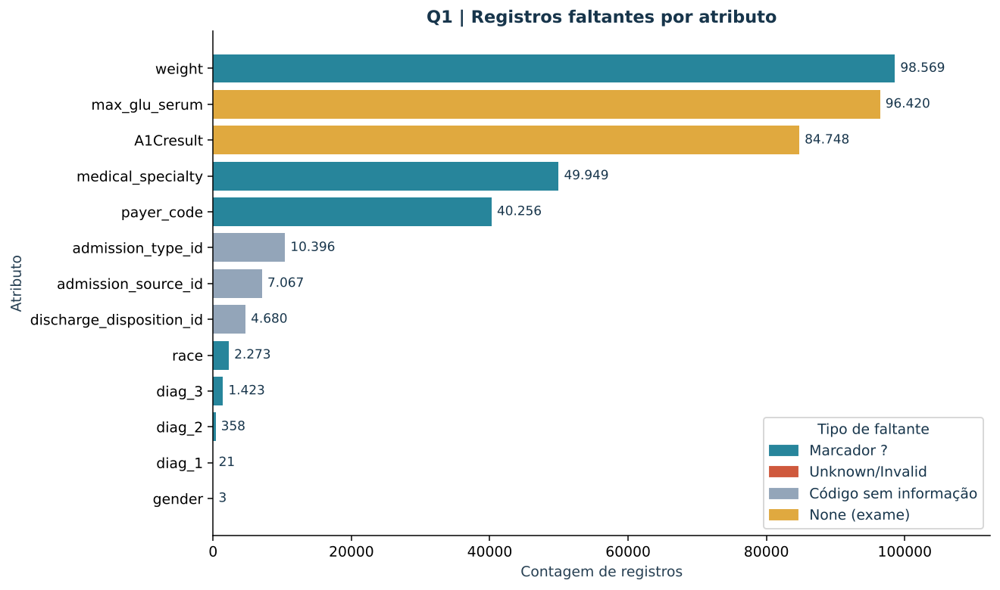

**O que mostra:** Contagem de registros faltantes por atributo, separada por tipo: marcador "?", Unknown/Invalid, código administrativo sem informação e None nos exames.

**Interpretação:** O peso falta em quase toda a base (98.569 registros). Especialidade e pagador faltam em cerca de metade e 40% das internações. O None de HbA1c e glicose é o segundo maior volume, mas significa exame não feito, e não dado perdido. Os demais faltantes são pequenos.

**Escolha visual:** Barras horizontais ordenadas da maior para a menor, para ler os nomes dos atributos sem girar o texto. A ordenação cria uma hierarquia visual: o olho começa pelo atributo mais crítico (weight, que falta em quase toda a base) e desce até os menores, sem precisar comparar barras espalhadas. A cor separa o tipo de faltante, porque cada tipo recebe tratamento diferente. Os rótulos trazem a contagem exata.

Exemplo de diagnóstico estratificado: ausência de especialidade por idade e desfecho.


,atributo,estratificador,grupo,n,faltantes,percentual
39,medical_specialty,age,[0-10),161,28,17.39%
40,medical_specialty,age,[10-20),691,228,33.00%
41,medical_specialty,age,[20-30),1657,742,44.78%
42,medical_specialty,age,[30-40),3775,1728,45.77%
43,medical_specialty,age,[40-50),9685,4468,46.13%
44,medical_specialty,age,[50-60),17256,8234,47.72%
45,medical_specialty,age,[60-70),22483,11121,49.46%
46,medical_specialty,age,[70-80),26068,12970,49.75%
47,medical_specialty,age,[80-90),17197,8995,52.31%
48,medical_specialty,age,[90-100),2793,1435,51.38%


A tabela completa de todos os padrões está em out/parte_especifica/padroes_ausencia.csv


In [5]:
display(Image(filename=str(figuras["Q1"]), width=850))
exibir_nota("Q1")
# [IA] Claude – percentual formatado
print("Exemplo de diagnóstico estratificado: ausência de especialidade por idade e desfecho.")
display(format_pct(tabelas["padroes_ausencia"].loc[lambda t: t.atributo.eq("medical_specialty")]))
print("A tabela completa de todos os padrões está em out/parte_especifica/padroes_ausencia.csv")


Atributos com faltantes: ['race', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3']


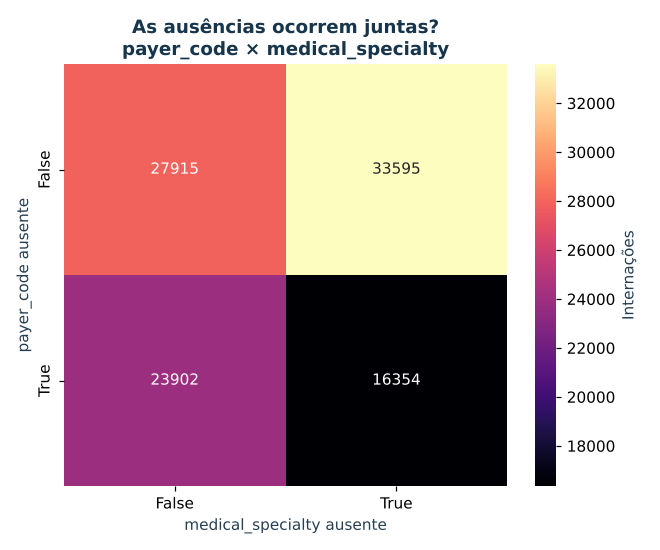

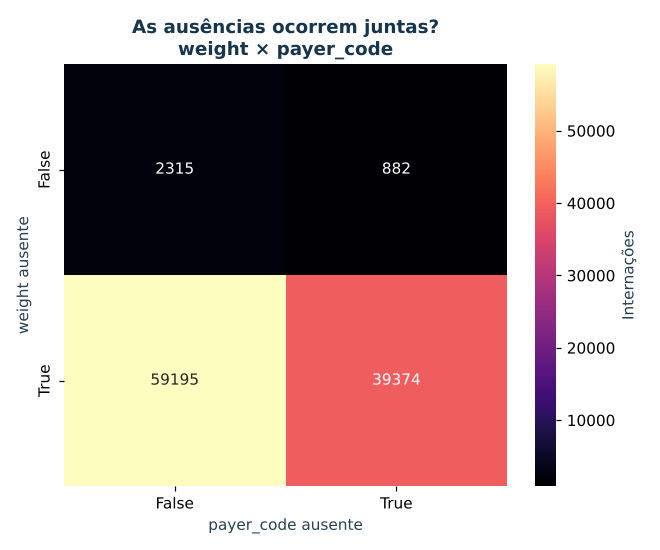

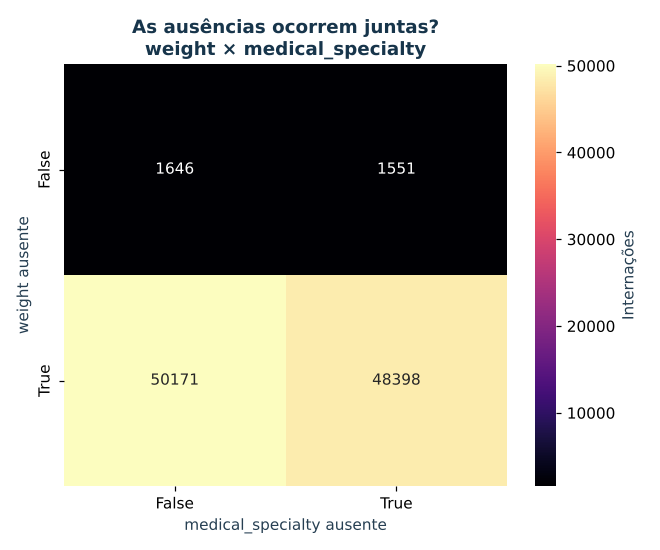

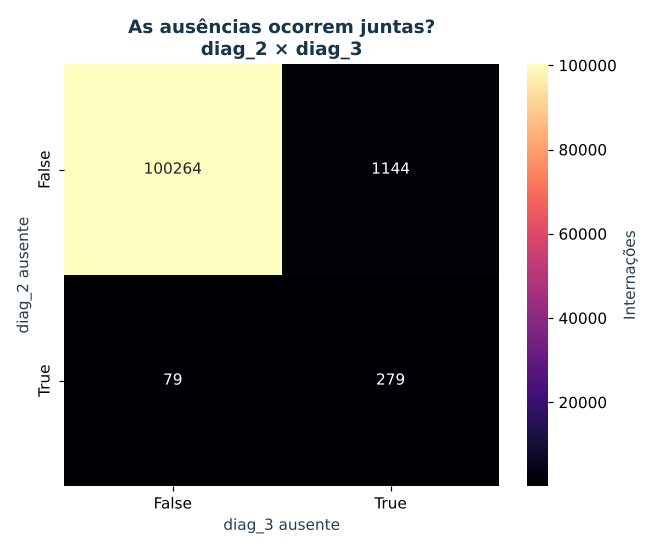

In [6]:
# [IA] Claude – heatmaps de ausência conjunta (movidos para a seção 5) corrigidos (indentação, imports e variáveis)
import io
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = raw.replace("?", np.nan)
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Atributos com faltantes:", cols_com_ausentes)
pares = [(a, b) for a, b in PARES_AUSENCIA if a in cols_com_ausentes and b in cols_com_ausentes]
for a, b in pares:
    tabela_contingencia = pd.crosstab(df[a].isna(), df[b].isna(),
                                      rownames=[f"{a} ausente"], colnames=[f"{b} ausente"])
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax,
                cbar_kws={"label": "Internações"})
    ax.set_title(f"As ausências ocorrem juntas?\n{a} × {b}")
    plt.tight_layout()
    # figuras.py usa o backend Agg, no qual plt.show() não exibe nada: mostra o PNG
    png = io.BytesIO()
    fig.savefig(png, format="png", dpi=110)
    display(Image(data=png.getvalue()))
    plt.close(fig)

## 6. Outliers: identificar, avaliar e justificar a decisão

Usamos a regra do IQR (abaixo de **Q1 − 1,5 × IQR** ou acima de **Q3 + 1,5 × IQR**) como triagem, e não como critério de exclusão: ser extremo não significa estar errado. Em contagens com muitos zeros, como emergências e consultas ambulatoriais, o IQR é zero, e qualquer valor positivo vira "outlier".

A regra do IQR sinaliza 45.358 ocorrências somando os oito atributos (a mesma internação pode ser contada mais de uma vez). Nas consultas ambulatoriais e nas emergências o IQR é zero, porque mais da metade das internações tem valor 0, e qualquer valor positivo vira "outlier" (16,4% e 11,2% das linhas). Em internações prévias o limite superior é 2,5. Assim, todo paciente com 3 ou mais internações seria sinalizado (6,9%), e esse é justamente o grupo com a maior taxa de reinternação em menos de 30 dias (25,7%). Remover esses casos apagaria o contraste que a pergunta quer estudar. Os valores também são plausíveis: a permanência fica entre 1 e 14 dias, e contagens altas de emergência correspondem a pacientes que usam muito o serviço. Decisão: preservar todos os valores e usar o IQR apenas como triagem.

Em seguida verificamos se os extremos de medicamentos e de internações prévias aparecem nas mesmas internações, o que poderia indicar um erro sistemático.

,atributo,min,q1,mediana,q3,max,iqr,limite_inferior,limite_superior,sinalizados_iqr,sinalizados_pct,p99,acima_p99
0,time_in_hospital,1.0,2.0,4.0,6.0,14.0,4.0,-4.0,12.0,2252,2.212920,14.0,0
1,num_lab_procedures,1.0,31.0,44.0,57.0,132.0,26.0,-8.0,96.0,143,0.140518,85.0,886
2,num_procedures,0.0,0.0,1.0,2.0,6.0,2.0,-3.0,5.0,4954,4.868031,6.0,0
3,num_medications,1.0,10.0,15.0,20.0,81.0,10.0,-5.0,35.0,2557,2.512627,43.0,960
4,number_outpatient,0.0,0.0,0.0,0.0,42.0,0.0,0.0,0.0,16739,16.448519,5.0,924
5,number_emergency,0.0,0.0,0.0,0.0,76.0,0.0,0.0,0.0,11383,11.185465,3.0,939
6,number_inpatient,0.0,0.0,0.0,1.0,21.0,1.0,-1.5,2.5,7049,6.926675,6.0,724
7,number_diagnoses,1.0,6.0,8.0,9.0,16.0,3.0,1.5,13.5,281,0.276124,9.0,115


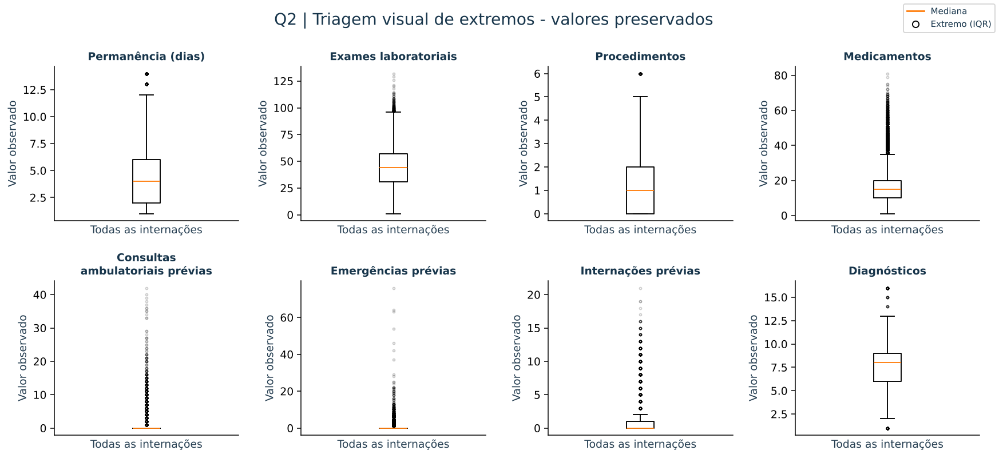

**O que mostra:** Um boxplot para cada uma das oito variáveis numéricas, usando todas as internações. Os pontos isolados são os valores além dos limites do IQR.

**Interpretação:** Em consultas ambulatoriais, emergências e internações prévias, quase todos os pontos acima da caixa são contagens plausíveis de uso do serviço, e não erros. Nas emergências, a caixa vira uma linha no zero. Permanência e procedimentos ficam presos aos limites do domínio. Exames laboratoriais têm alguns valores acima de 96, mas são poucos (0,14%).

**Escolha visual:** Escolhemos o boxplot porque ele mostra diretamente a mediana, os quartis e os pontos que a regra do IQR sinaliza. Cada variável tem seu próprio painel e sua própria escala, porque os intervalos são muito diferentes (0 a 6 procedimentos e até 132 exames).

In [7]:
# [IA] Claude – tabela de outliers sem a coluna decisao (texto automático antigo)
display(tabelas["outliers_iqr"].drop(columns="decisao"))
display(Image(filename=str(figuras["Q2"]), width=1000))
exibir_nota("Q2")
# [IA] Claude – exibição da tabela sensibilidade_log1p removida


Limite superior (IQR) – medicamentos: 35 | internações prévias: 2.5


Internações prévias extremo (> 2.5),False,True
Medicamentos extremo (> 35),,
False,92278,6931
True,2439,118


,internacoes,tambem_extremo_internacoes,percentual
Medicamentos extremo,,,
False,99209,6931,6.99%
True,2557,118,4.61%


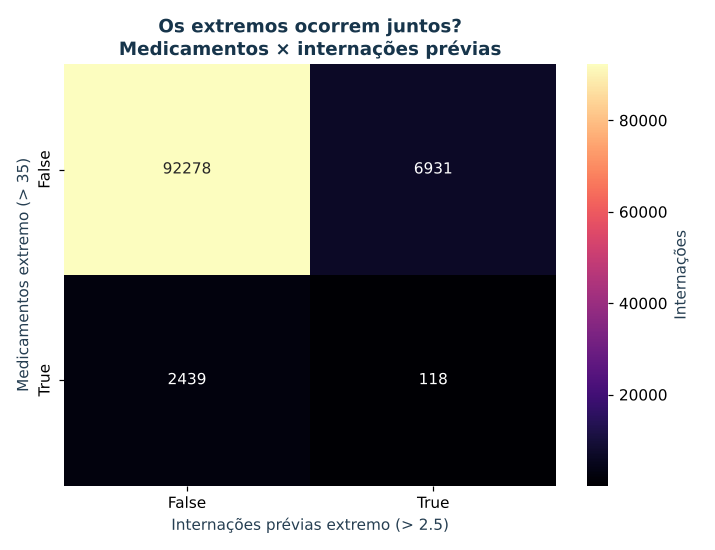

**O que mostra:** Tabela cruzada e mapa de calor das internações que passam do limite superior do IQR em medicamentos (mais de 35) e em internações prévias (mais de 2,5, ou seja, 3 ou mais). Só 118 internações são extremas nas duas variáveis ao mesmo tempo.

**Interpretação:** Os extremos não aparecem juntos. Entre as internações com muitos medicamentos, 4,6% também têm 3 ou mais internações prévias, contra 7,0% nas demais. Se os extremos fossem erro sistemático de digitação ou de carga, esperaríamos que se acumulassem nas mesmas linhas. Eles também se comportam de forma diferente em relação ao desfecho. A taxa de reinternação em menos de 30 dias é de 25,7% quando só o histórico é extremo, 11,5% quando só os medicamentos são extremos e 10,0% quando nenhum é. O histórico extremo carrega informação, por isso foi mantido.

**Escolha visual:** Tabela 2 × 2 com contagens absolutas no mapa de calor, para mostrar de imediato onde estão as internações. A escala magma deixa a célula grande (nenhum extremo) escura e realça as células pequenas. Os limites usados estão escritos nos rótulos dos eixos.

In [8]:
# [IA] Claude – extremos simultâneos: medicamentos × internações prévias (limites superiores do IQR)
import io
import matplotlib.pyplot as plt
import seaborn as sns

limites = tabelas["outliers_iqr"].set_index("atributo")["limite_superior"]
lim_med, lim_int = limites["num_medications"], limites["number_inpatient"]
extremo_med = raw["num_medications"].gt(lim_med)
extremo_int = raw["number_inpatient"].gt(lim_int)
print(f"Limite superior (IQR) – medicamentos: {lim_med:g} | internações prévias: {lim_int:g}")

tabela_extremos = pd.crosstab(extremo_med, extremo_int,
                              rownames=[f"Medicamentos extremo (> {lim_med:g})"],
                              colnames=[f"Internações prévias extremo (> {lim_int:g})"])
display(tabela_extremos)

# Percentual de cada grupo de medicamentos que também é extremo em internações prévias
resumo_extremos = (pd.DataFrame({"Medicamentos extremo": extremo_med, "Internações extremo": extremo_int})
                   .groupby("Medicamentos extremo")["Internações extremo"]
                   .agg(internacoes="size", tambem_extremo_internacoes="sum"))
resumo_extremos["percentual"] = (resumo_extremos.tambem_extremo_internacoes / resumo_extremos.internacoes * 100).map(lambda v: f"{v:.2f}%")
display(resumo_extremos)

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(tabela_extremos, annot=True, fmt="d", cmap="magma", ax=ax, cbar_kws={"label": "Internações"})
ax.set_title("Os extremos ocorrem juntos?\nMedicamentos × internações prévias")
plt.tight_layout()
png = io.BytesIO()
fig.savefig(png, format="png", dpi=110)
display(Image(data=png.getvalue()))
plt.close(fig)
nota = TG.EXTREMOS_SIMULTANEOS
display(Markdown("**O que mostra:** " + nota["o_que_mostra"] + "\n\n**Interpretação:** " + nota["interpretacao"] + "\n\n**Escolha visual:** " + nota["escolha_visual"]))


## 7. Distribuições: quatro visualizações exploratórias e cobertura completa

Aqui olhamos a forma de cada variável e comparamos os três desfechos. E1 mostra a composição etária, E3 o número de medicamentos, e H1 e H2 os histogramas das oito variáveis numéricas por desfecho. A1 resume as mesmas variáveis em curvas acumuladas, e as páginas A2 cobrem os 40 atributos categóricos, incluindo o desfecho. E2 e E4 aparecem na seção 8, junto com as relações com o alvo.

As distribuições mostram uma base concentrada em pacientes idosos (47,7% entre 60 e 80 anos) e mulheres (53,8%), com internações curtas (mediana de 4 dias) e cerca de 15 medicamentos. As contagens de histórico têm muitos zeros. Nas variáveis categóricas, a maior parte dos 23 medicamentos quase não varia (mais de 99% "No" em vários deles, e examide e citoglipton têm uma única categoria). Os exames HbA1c e glicose quase sempre aparecem como "não realizados". O desfecho se divide em 53,9% NO, 34,9% >30 e 11,2% <30: a classe de interesse é minoritária, por isso comparamos proporções e não contagens absolutas.

### E1 · Distribuição etária

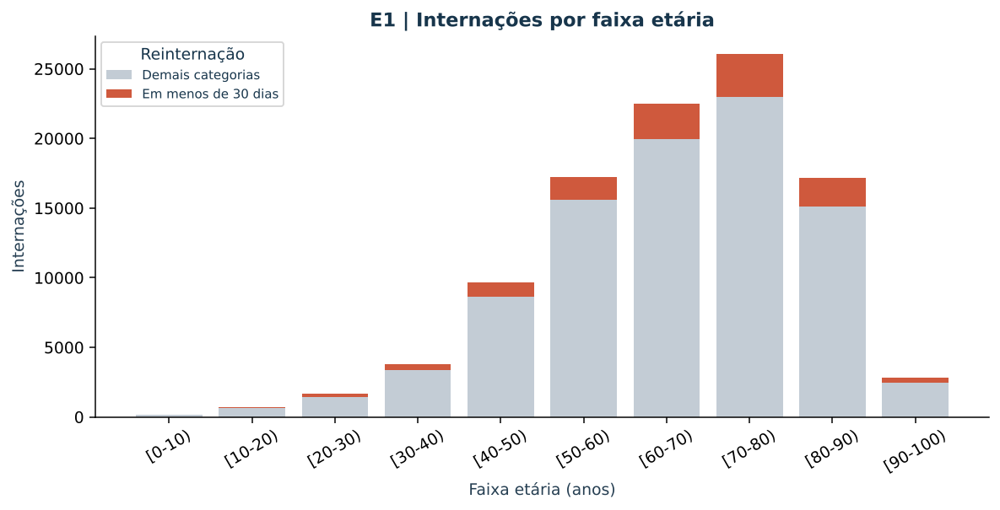

**O que mostra:** Número de internações por faixa etária de dez anos, com a parte de reinternações em menos de 30 dias empilhada em laranja.

**Interpretação:** A base é de pacientes mais velhos: 25,6% das internações estão entre 70 e 80 anos e 81,6% entre 50 e 90. A fatia laranja acompanha o tamanho de cada faixa. A taxa fica entre 9,7% e 12,1% dos 30 aos 100 anos, com pico de 14,2% entre 20 e 30 anos, uma faixa pequena (1.657 internações). A idade, sozinha, não separa bem quem volta rápido.

**Escolha visual:** Barras empilhadas em duas cores mostram o volume de cada faixa e, ao mesmo tempo, a parte que volta em menos de 30 dias. O eixo x segue a ordem natural das faixas, e o laranja é a cor do desfecho de interesse em todo o projeto.

### E3 · Medicamentos por internação

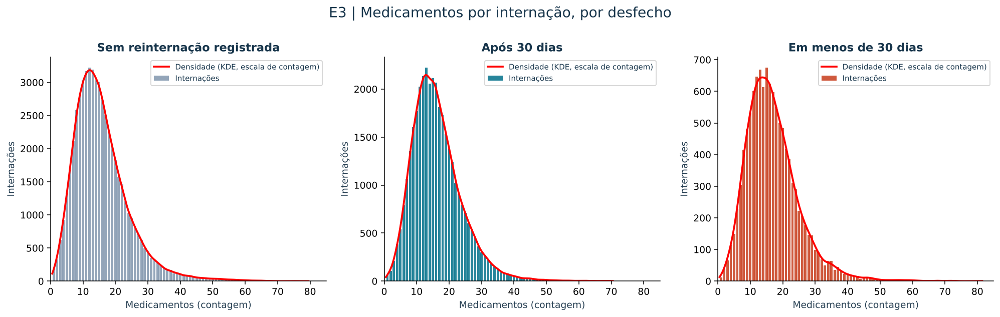

**O que mostra:** Distribuição do número de medicamentos por internação em três painéis, um por desfecho, com a curva de densidade (KDE) em vermelho na escala de contagem.

**Interpretação:** As três distribuições têm a mesma forma: assimétricas à direita, com pico entre 10 e 20 medicamentos e cauda até cerca de 80. A mediana sobe pouco de NO (14) para >30 (15) e <30 (16). Como as alturas refletem o tamanho de cada grupo, o que importa comparar é a forma, e ela quase não muda.

**Escolha visual:** Um painel por desfecho evita sobrepor barras de grupos com tamanhos muito diferentes. A cor de cada painel é a cor do desfecho, e a KDE em vermelho contrasta com as barras para destacar a forma. O eixo x é o mesmo (0 a 85) nos três painéis.

### H1 · Histogramas numéricos por desfecho - parte 1

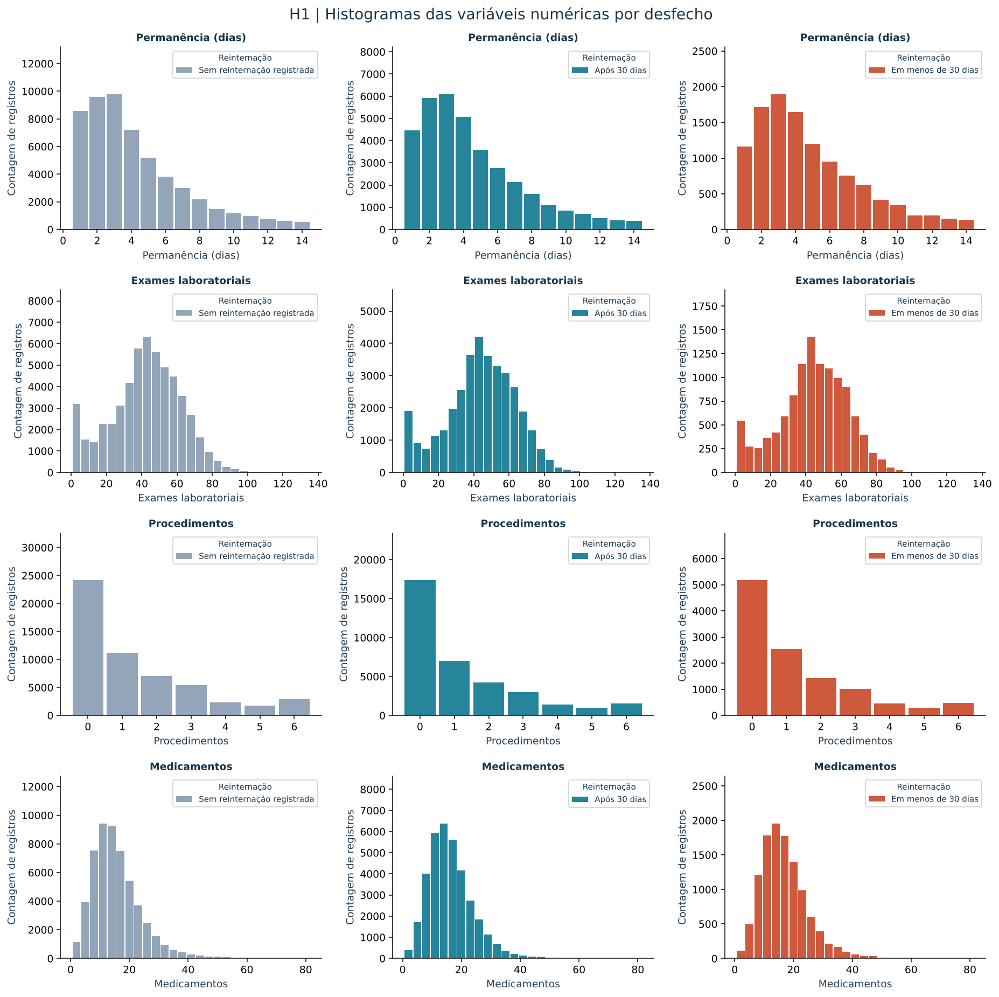

**O que mostra:** Histogramas de permanência, exames laboratoriais, procedimentos e medicamentos, com um painel para cada desfecho.

**Interpretação:** As formas são parecidas nos três desfechos. As diferenças de altura vêm principalmente do tamanho dos grupos (NO é cerca de cinco vezes maior que <30). Nenhuma dessas quatro variáveis do período da internação mostra um deslocamento claro no grupo <30.

**Escolha visual:** Grade de linhas (variáveis) por colunas (desfechos), com eixo x compartilhado em cada linha. Assim, a comparação entre desfechos é feita na mesma escala horizontal. As cores são as mesmas dos demais gráficos.

### H2 · Histogramas numéricos por desfecho - parte 2

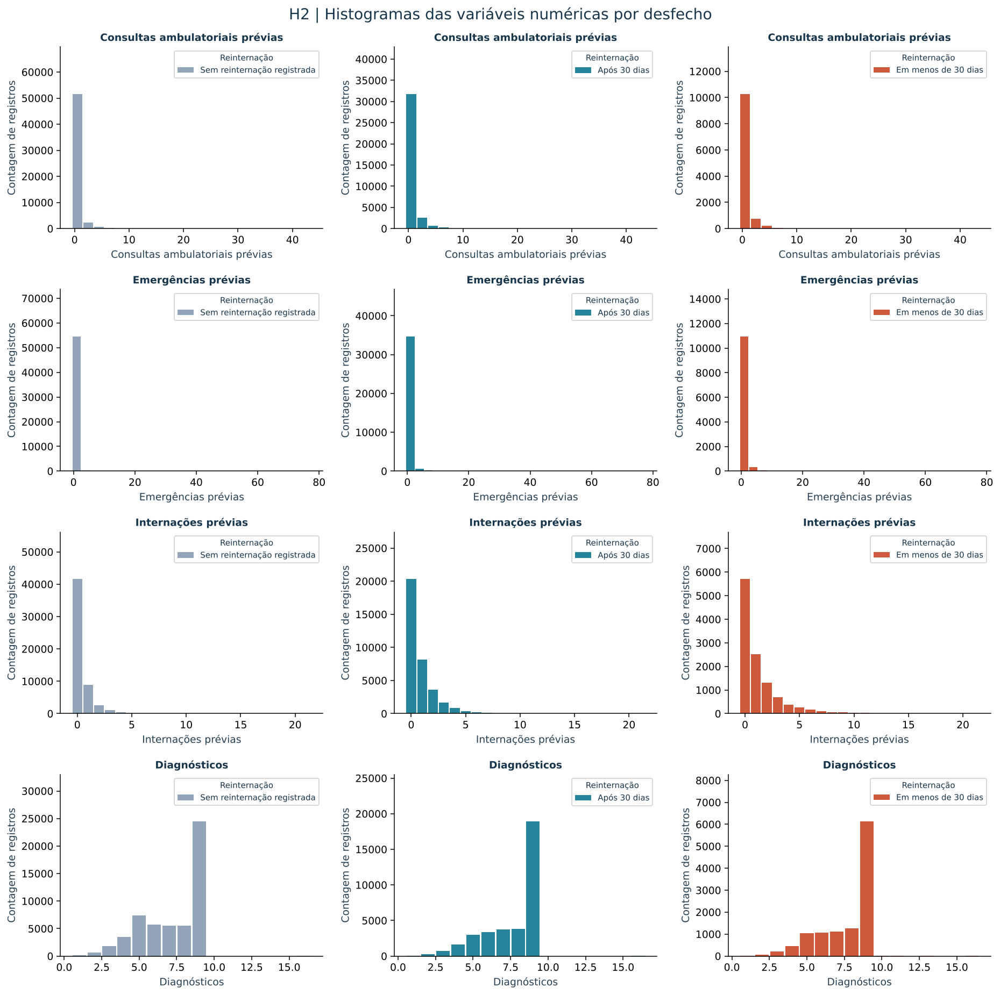

**O que mostra:** Histogramas de consultas ambulatoriais, emergências, internações prévias e diagnósticos, com um painel para cada desfecho.

**Interpretação:** As três contagens de histórico se concentram no zero, mas a cauda das internações prévias é proporcionalmente mais pesada em <30: 49,8% desse grupo teve ao menos uma internação no ano anterior, contra 24,2% em NO. Os diagnósticos se acumulam no valor 9 em todos os desfechos.

**Escolha visual:** Mesma grade do H1, para manter a leitura consistente. Barras espaçadas deixam claro que as variáveis são contagens discretas.

In [9]:
# [IA] Claude – inclui os histogramas por desfecho (H1 e H2); E2 passou para a seção 8
for chave in ["E1", "E3", "H1", "H2"]:
    display(Markdown("### " + chave + " · " + notas[chave]["titulo"]))
    display(Image(filename=str(figuras[chave]), width=850))
    exibir_nota(chave)


,atributo,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
0,time_in_hospital,101766.0,4.395987,2.985108,1.0,1.0,2.0,4.0,6.0,11.0,14.0,14.0
1,num_lab_procedures,101766.0,43.095641,19.674362,1.0,1.0,31.0,44.0,57.0,73.0,85.0,132.0
2,num_procedures,101766.0,1.339730,1.705807,0.0,0.0,0.0,1.0,2.0,5.0,6.0,6.0
3,num_medications,101766.0,16.021844,8.127566,1.0,3.0,10.0,15.0,20.0,31.0,43.0,81.0
4,number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,0.0,2.0,5.0,42.0
5,number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,0.0,1.0,3.0,76.0
6,number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,0.0,1.0,3.0,6.0,21.0
7,number_diagnoses,101766.0,7.422607,1.933600,1.0,2.0,6.0,8.0,9.0,9.0,9.0,16.0


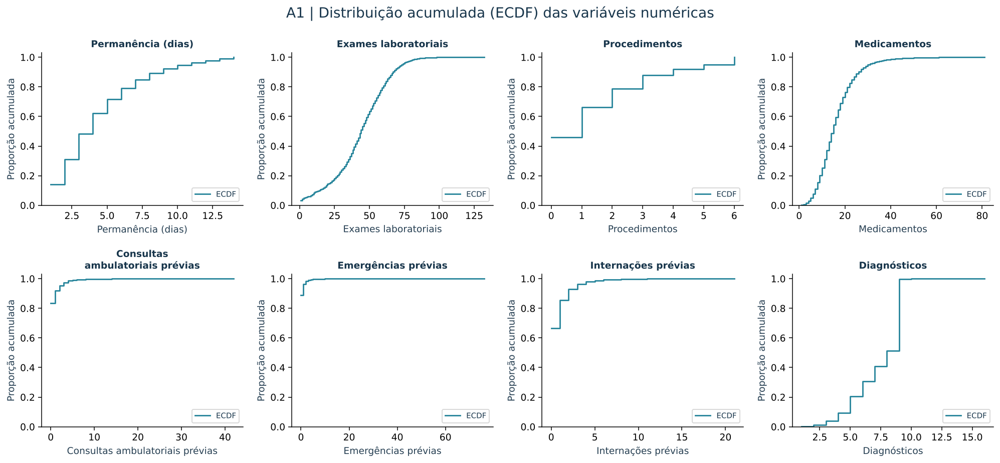

**O que mostra:** Distribuição acumulada empírica (ECDF) das oito variáveis numéricas: para cada valor, a proporção de internações com valor menor ou igual a ele.

**Interpretação:** As curvas de histórico sobem quase até o topo no zero: 66,5% das internações não tiveram internação prévia, 88,8% não tiveram emergência e 83,6% não tiveram consulta ambulatorial. Medicamentos e exames sobem de forma gradual. Cerca de 76% das internações usam até 20 medicamentos.

**Escolha visual:** A ECDF mostra a distribuição inteira sem escolher número de classes e permite ler percentis diretamente no eixo y. Uma curva por painel evita misturar escalas diferentes.

In [10]:
display(tabelas["descritiva_numerica"])
# [IA] Claude – A1 agora mostra curvas ECDF
display(Image(filename=str(figuras["A1"]), width=1000))
exibir_nota("A1")


Atributos categóricos com frequências completas: 40


,atributo,valor,n,percentual
2431,A1Cresult,None,84748,83.277322
2475,acarbose,No,101458,99.697345
2455,acetohexamide,No,101765,99.999017
63,admission_source_id,7,57494,56.496276
29,admission_type_id,1,53990,53.053083
9,age,[70-80),26068,25.615628
2506,change,No,54755,53.804807
2447,chlorpropamide,No,101680,99.915492
2489,citoglipton,No,101766,100.000000
2508,diabetesMed,Yes,78363,77.003125


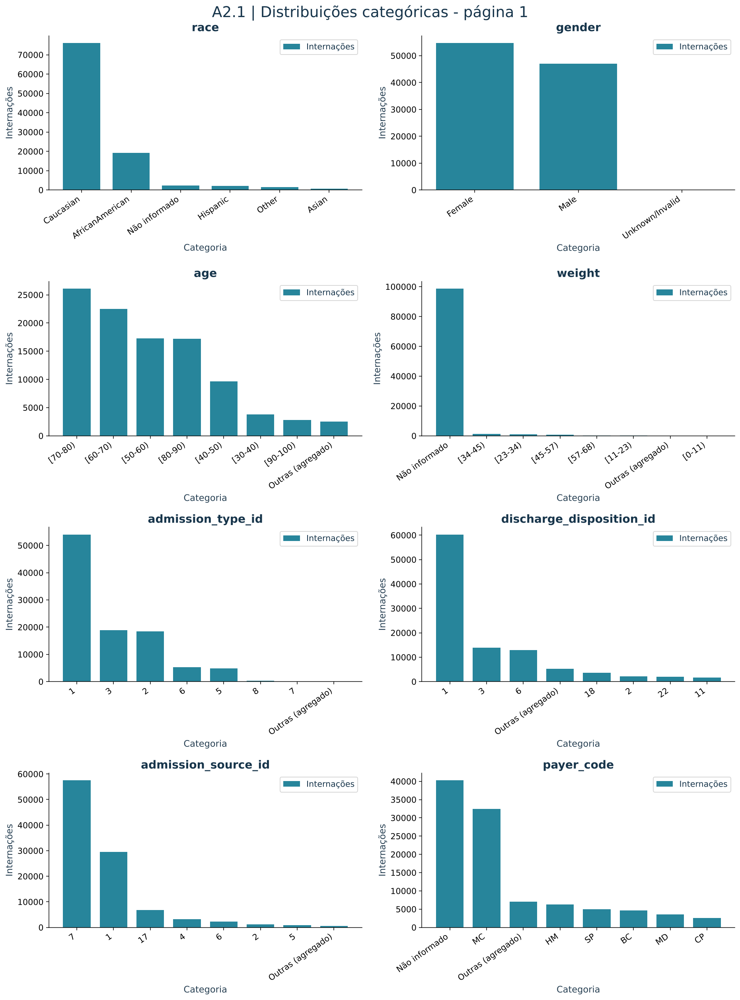

**O que mostra:** Frequências de race, gender, age, weight, admission_type_id, discharge_disposition_id, admission_source_id e payer_code.

**Interpretação:** Predominam pacientes Caucasian (74,8%) e mulheres (53,8%). O peso é "Não informado" em 96,9% dos casos. A admissão de emergência (código 1) responde por 53,1% e a alta para casa (código 1) por 59,2%. Em payer_code, "Não informado" (39,6%) supera o Medicare (31,9%).

**Escolha visual:** Barras verticais ordenadas por frequência. Os códigos administrativos aparecem como categorias, e não como números, porque são nominais.

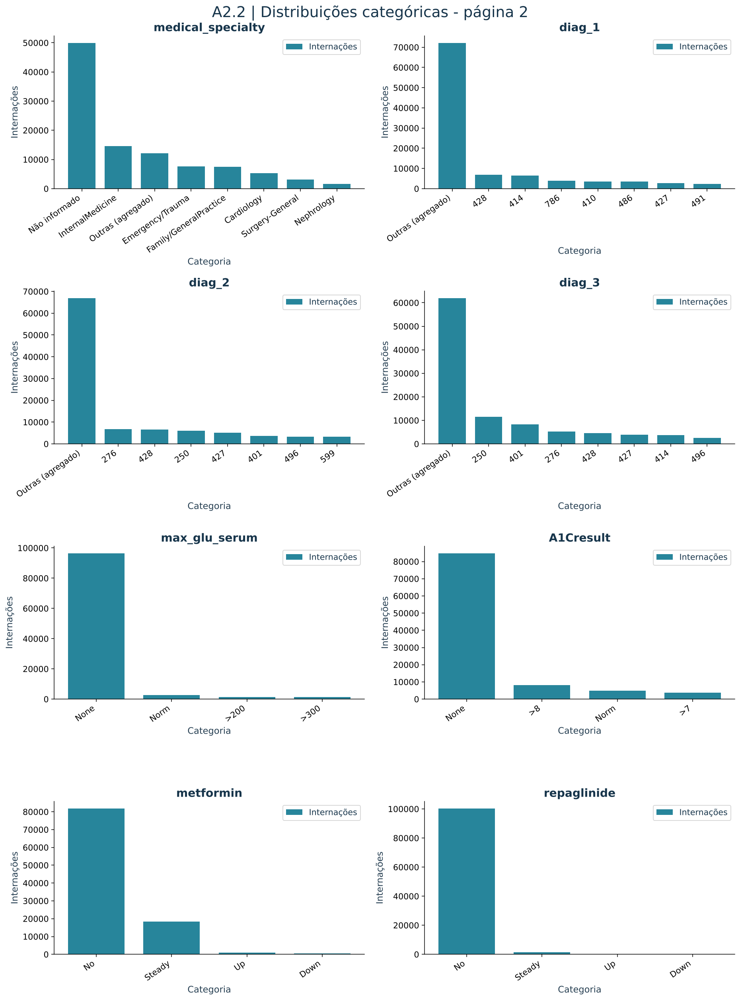

**O que mostra:** Frequências de medical_specialty, diag_1, diag_2, diag_3, max_glu_serum, A1Cresult, metformin e repaglinide.

**Interpretação:** A especialidade mais comum é "Não informado" (49,1%), seguida de medicina interna (14,4%). Os diagnósticos têm centenas de códigos, e o mais frequente (428, insuficiência cardíaca) não passa de 7%. Glicose e HbA1c não foram medidas em 94,7% e 83,3% das internações. A metformina é usada em cerca de 20%.

**Escolha visual:** A agregação em "Outras" é necessária para os diagnósticos, com mais de 700 códigos cada. Sem ela o gráfico ficaria ilegível.

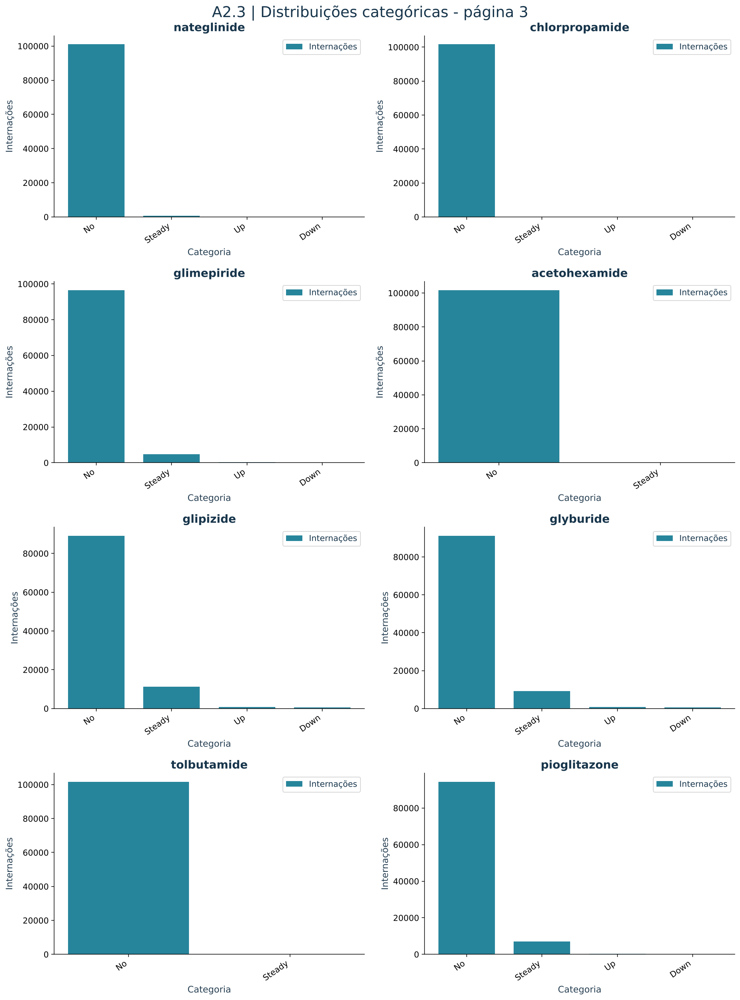

**O que mostra:** Frequências de nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide e pioglitazone.

**Interpretação:** Quase todos os registros são "No". Glipizide (11,2% Steady) e glyburide (9,1%) são os mais usados nesta página. Acetohexamide e tolbutamide praticamente não aparecem.

**Escolha visual:** Mesmo formato das outras páginas, para facilitar a comparação. O eixo y em contagem deixa evidente a dominância do "No".

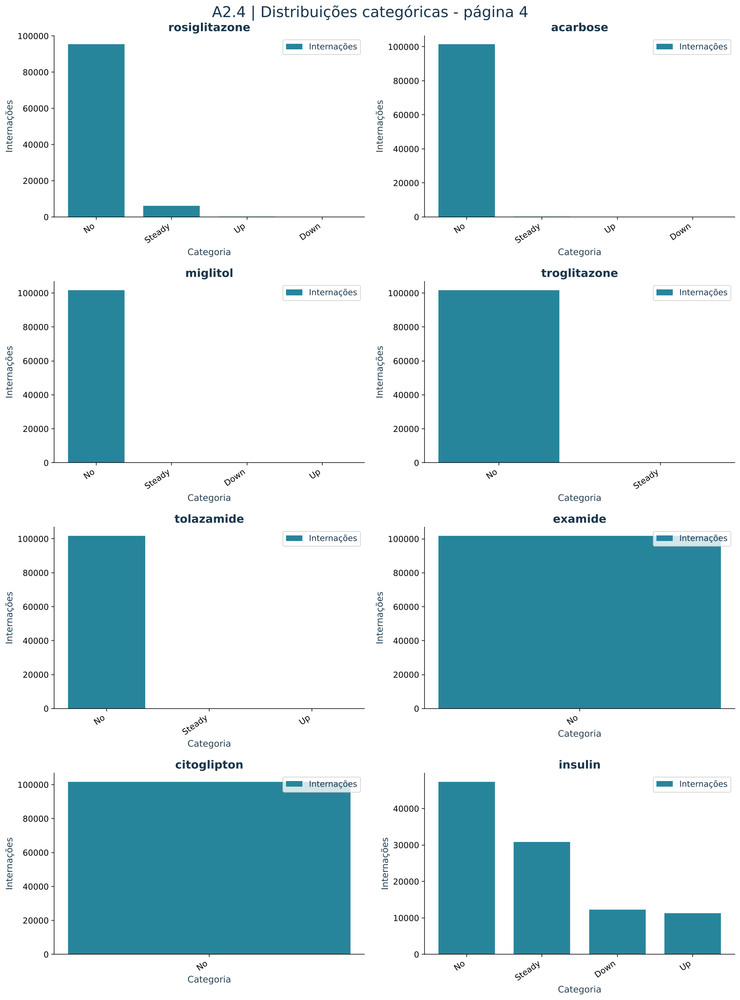

**O que mostra:** Frequências de rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton e insulin.

**Interpretação:** A insulina é a exceção: só 46,6% "No", com 30,3% Steady, 12,0% Down e 11,1% Up. Examide e citoglipton têm uma única categoria em toda a base, e as outras ficam próximas de 100% "No".

**Escolha visual:** Mesmo formato das outras páginas. Variáveis constantes foram mantidas no gráfico, para documentar que foram verificadas.

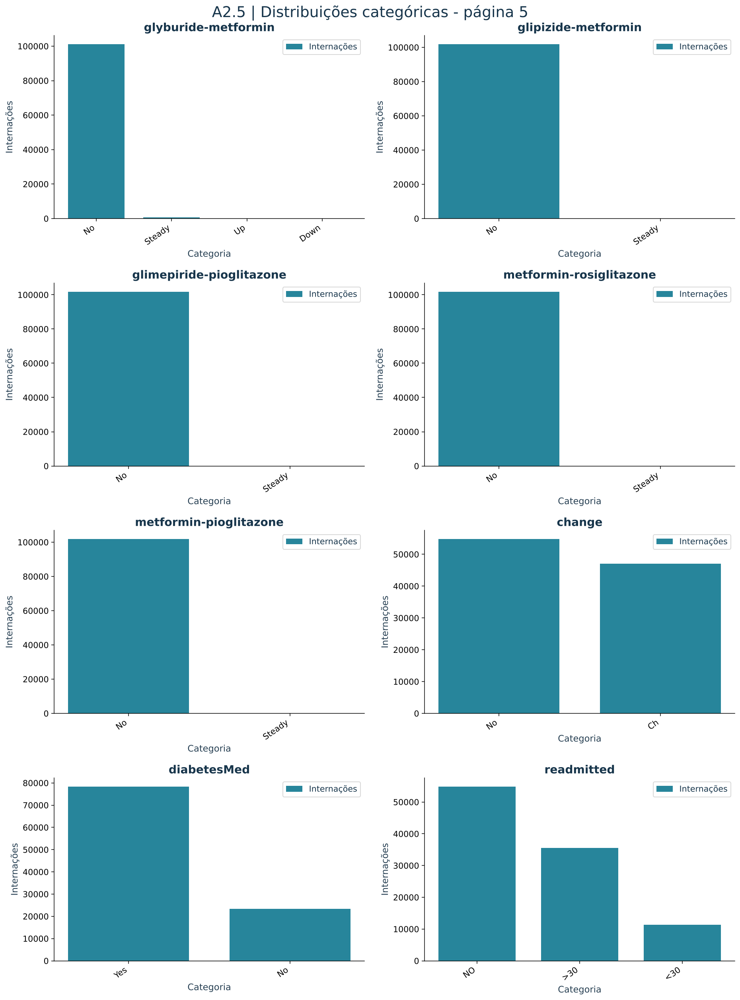

**O que mostra:** Frequências das combinações de medicamentos, de change, de diabetesMed e do desfecho readmitted.

**Interpretação:** As combinações são raríssimas. Houve mudança na medicação de diabetes em 46,2% das internações, e 77,0% receberam algum medicamento para diabetes. O desfecho se divide em 53,9% NO, 34,9% >30 e 11,2% <30.

**Escolha visual:** Mesmo formato das outras páginas. A página termina com o desfecho, que serve de referência para todas as proporções do projeto.

Outras é agregação apenas da apresentação. Todas as categorias estão no CSV frequencias_categoricas.csv.


In [11]:
frequencias = tabelas["frequencias_categoricas"]
print("Atributos categóricos com frequências completas:", frequencias.atributo.nunique())
display(frequencias.sort_values("n", ascending=False).drop_duplicates("atributo").sort_values("atributo"))
for pagina in range(1, 6):
    chave = f"A2_{pagina}"
    display(Image(filename=str(figuras[chave]), width=1000))
    exibir_nota(chave)
print("Outras é agregação apenas da apresentação. Todas as categorias estão no CSV frequencias_categoricas.csv.")


## 8. Relações com o alvo e análise multivariada

As seções anteriores mostraram que as variáveis do período da internação (permanência, medicamentos, exames) quase não diferenciam os desfechos. Aqui procuramos onde está a diferença. Para os 47 atributos explicativos, calculamos médias e medianas por desfecho (numéricos) e a proporção de reinternação em menos de 30 dias por categoria (categóricos). E4 compara as correlações de Pearson e Spearman dentro de cada classe.

M1 e M2 cruzam duas variáveis ao mesmo tempo com o desfecho: idade × internações prévias e internações prévias × emergências prévias. O M2 responde à segunda parte da pergunta. Os cruzamentos são descritivos e não fazem ajuste causal. No fim da seção, testamos se o resultado muda com outras coortes e sem as linhas `NO` (C1).

Atributos cobertos: 47


,atributo,grupos descritos
0,A1Cresult,4
1,acarbose,4
2,acetohexamide,2
3,admission_source_id,17
4,admission_type_id,8
5,age,10
6,change,2
7,chlorpropamide,4
8,citoglipton,1
9,diabetesMed,2


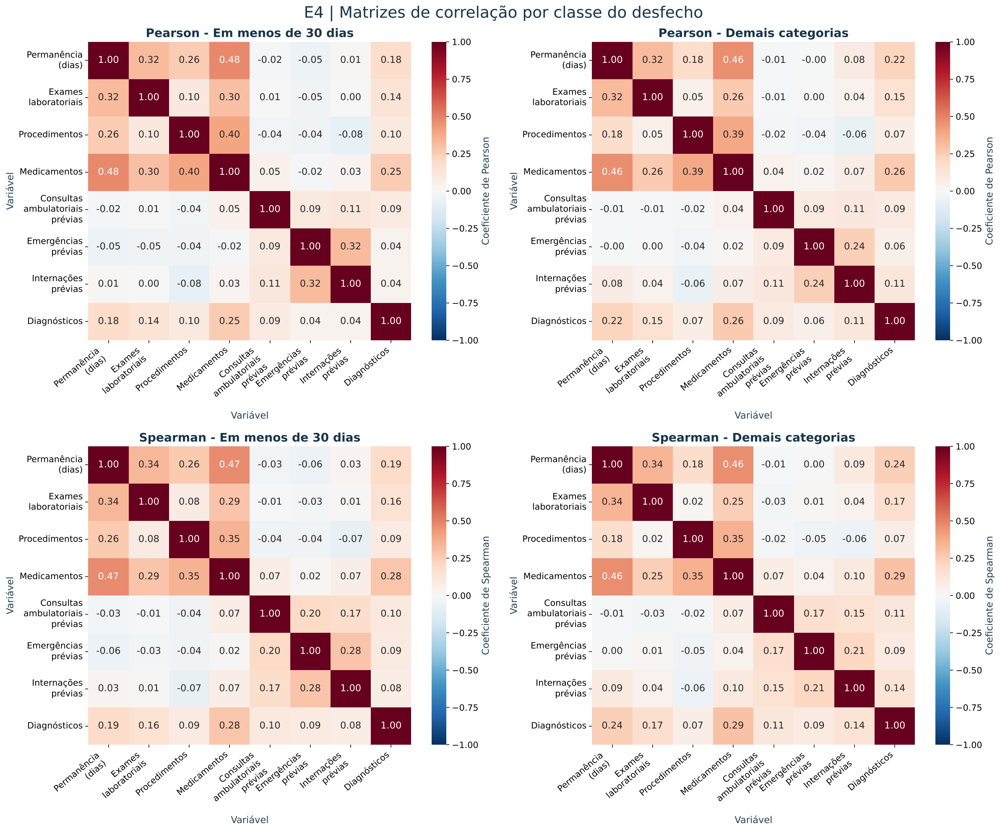

**O que mostra:** Quatro matrizes de correlação entre as oito variáveis numéricas: Pearson e Spearman, calculadas separadamente para <30 dias e para as demais categorias.

**Interpretação:** Nenhuma correlação é forte. A maior é entre permanência e medicamentos (0,46 a 0,48). A diferença mais interessante está entre internações e emergências prévias: a correlação é de 0,32 (Pearson) no grupo <30 e de 0,24 nas demais. Entre quem volta rápido, os dois históricos andam mais juntos, o que motivou o cruzamento M2. Pearson e Spearman dão resultados parecidos, então as conclusões não dependem dos extremos.

**Escolha visual:** Mapa de calor com escala divergente fixa de -1 a 1 (azul negativo, vermelho positivo), igual nos quatro painéis, para que as cores sejam comparáveis. Os valores aparecem em cada célula, porque as diferenças são pequenas.

### E2 · Permanência por desfecho

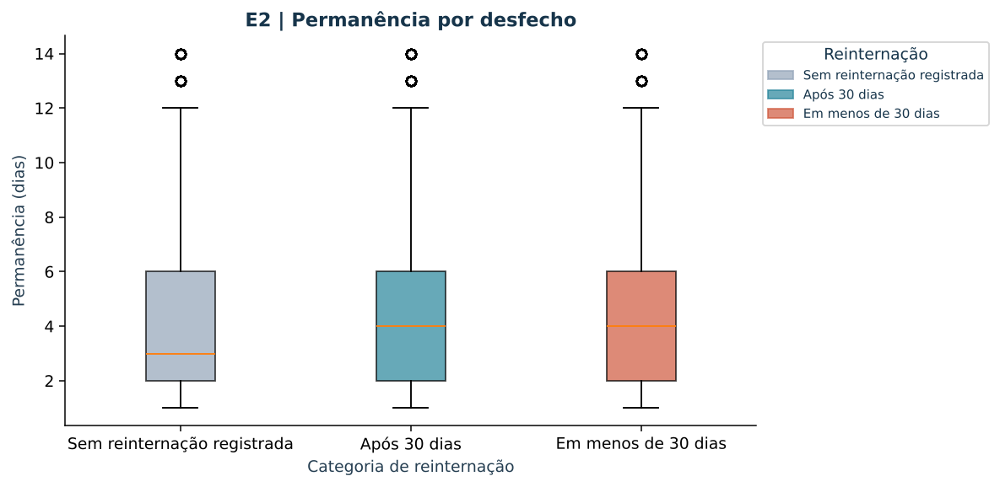

**O que mostra:** Boxplot da permanência hospitalar em dias para cada desfecho: sem reinternação registrada, após 30 dias e em menos de 30 dias.

**Interpretação:** As medianas são quase iguais: 4 dias para <30 e >30 e 3 dias para quem não foi reinternado. As caixas se sobrepõem bastante. A média é um pouco maior em <30 (4,77 dias, contra 4,35 nas demais). A permanência tem relação fraca com a reinternação rápida e não diferencia os grupos tão bem quanto o histórico.

**Escolha visual:** Os três boxplots ficam lado a lado e na mesma escala, para comparar mediana e dispersão. Cada caixa usa a cor do seu desfecho, a mesma dos outros gráficos.

In [12]:
relacoes = tabelas["relacoes_com_alvo"]
print("Atributos cobertos:", relacoes.atributo.nunique())
display(relacoes.groupby("atributo").size().rename("grupos descritos").reset_index())
# [IA] Claude – matrizes de Pearson e Spearman por classe (4 heatmaps em E4)
display(Image(filename=str(figuras["E4"]), width=1100))
exibir_nota("E4")
# [IA] Claude – E2 (boxplot de permanência por desfecho) movido da seção 7 para a seção 8
display(Markdown("### E2 · " + notas["E2"]["titulo"]))
display(Image(filename=str(figuras["E2"]), width=850))
exibir_nota("E2")


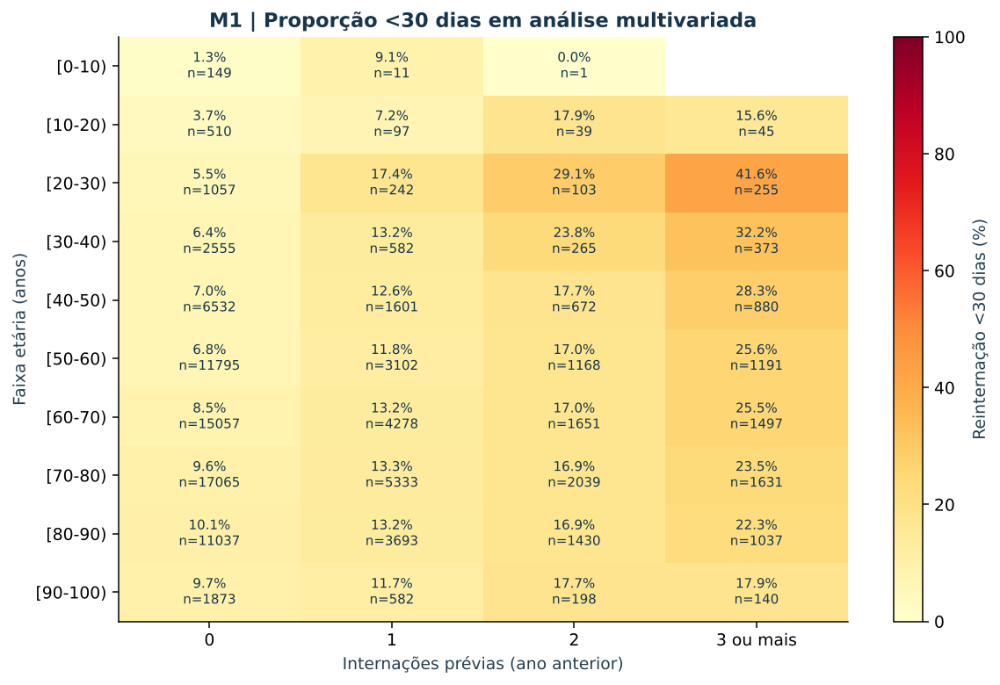

**O que mostra:** Mapa de calor em que as linhas são faixas etárias e as colunas são grupos de internações prévias (0, 1, 2, 3 ou mais). Cada célula mostra a porcentagem de reinternação em menos de 30 dias e o número de internações (n).

**Interpretação:** Na base integral: em quase todas as faixas etárias, a taxa sobe da esquerda para a direita, de 0 até 3 ou mais internações prévias. Entre 70 e 80 anos, por exemplo, vai de 9,6% para 23,5%. O efeito do histórico não é explicado pela idade. As células mais escuras (41,6% entre 20 e 30 anos com 3 ou mais) têm denominadores pequenos e devem ser lidas com cautela.

**Escolha visual:** A escala de cor é fixa de 0 a 100%, para que a mesma cor signifique a mesma taxa em qualquer recorte. O n aparece em cada célula para que uma célula escura com poucos casos não seja lida como resultado forte.

,age,grupo_internacoes,n,casos,taxa,percentual
0,[0-10),0,149,2,0.013423,1.342282
1,[0-10),1,11,1,0.090909,9.090909
2,[0-10),2,1,0,0.000000,0.000000
3,[10-20),0,510,19,0.037255,3.725490
4,[10-20),1,97,7,0.072165,7.216495
5,[10-20),2,39,7,0.179487,17.948718
6,[10-20),3 ou mais,45,7,0.155556,15.555556
7,[20-30),0,1057,58,0.054872,5.487228
8,[20-30),1,242,42,0.173554,17.355372
9,[20-30),2,103,30,0.291262,29.126214


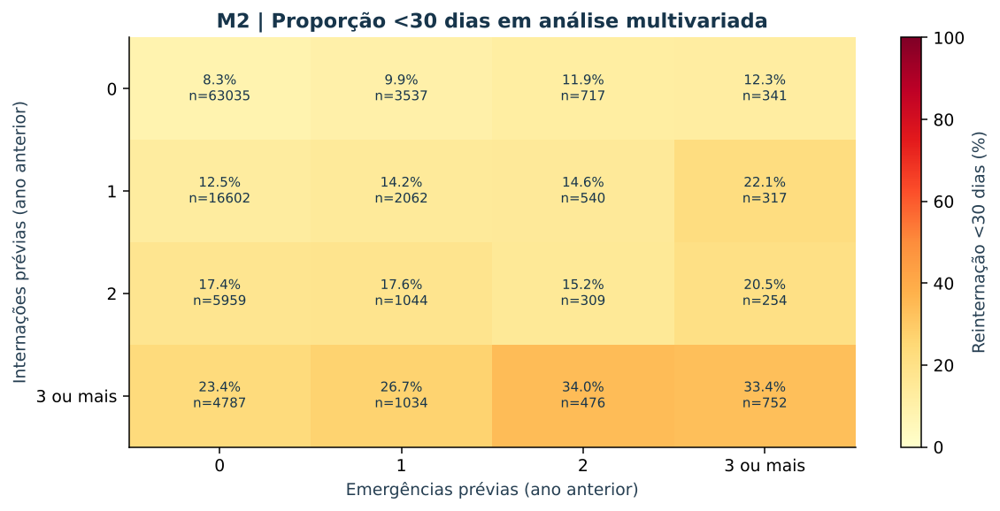

**O que mostra:** Mapa de calor em que as linhas são os grupos de internações prévias e as colunas os grupos de emergências prévias. Cada célula mostra a porcentagem de reinternação em menos de 30 dias e o n.

**Interpretação:** Na base integral: os dois históricos somam risco. Quem não teve internação nem emergência no ano anterior volta em menos de 30 dias em 8,3% dos casos. Com 3 ou mais internações e 3 ou mais emergências, a taxa é de 33,4% (n=752), quatro vezes maior. As internações prévias pesam mais: sem nenhuma emergência, a taxa já vai de 8,3% para 23,4% quando as internações passam de 0 para 3 ou mais. As emergências acrescentam um efeito menor e menos regular (na linha de 2 internações, a taxa oscila entre 15,2% e 20,5%).

**Escolha visual:** Usamos o mesmo formato e a mesma escala fixa do M1. Cruzar os dois históricos numa única grade permite ver se o risco aumenta quando o paciente tem os dois ao mesmo tempo. O n em cada célula indica onde os grupos são pequenos.

,grupo_internacoes,grupo_emergencias,n,casos,taxa,percentual
0,0,0,63035,5229,0.082954,8.295391
1,0,1,3537,350,0.098954,9.895392
2,0,2,717,85,0.118550,11.854951
3,0,3 ou mais,341,42,0.123167,12.316716
4,1,0,16602,2082,0.125407,12.540658
5,1,1,2062,292,0.141610,14.161009
6,1,2,540,79,0.146296,14.629630
7,1,3 ou mais,317,70,0.220820,22.082019
8,2,0,5959,1036,0.173855,17.385467
9,2,1,1044,184,0.176245,17.624521


In [13]:
for chave, tabela in [("M1", "multivariada_idade_historico"), ("M2", "multivariada_dois_historicos")]:
    display(Image(filename=str(figuras[chave]), width=850))
    exibir_nota(chave)
    display(tabelas[tabela])


### Sensibilidade à composição da coorte

Para saber se o resultado depende de como a base é montada, recalculamos as taxas por histórico em quatro coortes: todas as internações; uma linha por paciente (menor `encounter_id`); sem altas por óbito ou hospice; e a combinação das duas últimas escolhas. O menor ID não garante que seja a primeira internação no tempo. Os resultados são descritivos: não aplicamos testes de significância que suponham internações independentes, porque o mesmo paciente se repete.

Com 3 ou mais internações prévias, a taxa fica entre 25,7% e 26,5% em todas as coortes. Com 3 ou mais emergências, a taxa cai de 24,9% para 16,1% quando usamos uma linha por paciente: parte do efeito das emergências vem de pacientes que aparecem muitas vezes na base.

In [14]:
display(tabelas["sensibilidade_coortes"])


,coorte,variavel,grupo,n,casos,taxa,percentual
0,Todas as internações,number_inpatient,0,67630,5706,0.084371,8.437084
1,Todas as internações,number_inpatient,1,19521,2523,0.129245,12.924543
2,Todas as internações,number_inpatient,2,7566,1319,0.174333,17.433254
3,Todas as internações,number_inpatient,3 ou mais,7049,1809,0.256632,25.663215
4,Todas as internações,number_emergency,0,90383,9467,0.104743,10.474315
5,Todas as internações,number_emergency,1,7677,1102,0.143546,14.354566
6,Todas as internações,number_emergency,2,2042,373,0.182664,18.266405
7,Todas as internações,number_emergency,3 ou mais,1664,415,0.249399,24.939904
8,Menor encounter_id por paciente,number_inpatient,0,63077,5025,0.079665,7.966454
9,Menor encounter_id por paciente,number_inpatient,1,5962,748,0.125461,12.546125


### Comparação das bases: com e sem as linhas "NO" (C1)

A base principal segue o artigo original: compara quem voltou em menos de 30 dias com todos os demais, que reúnem quem voltou depois de 30 dias (>30) e quem não tem reinternação registrada (NO). Para responder à terceira parte da pergunta, refizemos as taxas só com os pacientes que voltaram ao hospital em algum momento, retirando as linhas NO. Nessa base de 46.902 internações, a pergunta passa a ser: entre quem volta, quem volta mais rápido? A taxa geral sobe para 24,2%, porque o denominador fica menor. Por isso, o que interessa comparar é a inclinação entre os grupos, e não o nível das barras.

,base,variavel,grupo,n,casos,percentual
0,Todas as internações (com NO),Internações prévias (ano anterior),0,67630,5706,8.44%
1,Todas as internações (com NO),Internações prévias (ano anterior),1,19521,2523,12.92%
2,Todas as internações (com NO),Internações prévias (ano anterior),2,7566,1319,17.43%
3,Todas as internações (com NO),Internações prévias (ano anterior),3 ou mais,7049,1809,25.66%
4,Todas as internações (com NO),Emergências prévias (ano anterior),0,90383,9467,10.47%
5,Todas as internações (com NO),Emergências prévias (ano anterior),1,7677,1102,14.35%
6,Todas as internações (com NO),Emergências prévias (ano anterior),2,2042,373,18.27%
7,Todas as internações (com NO),Emergências prévias (ano anterior),3 ou mais,1664,415,24.94%
8,Somente reinternados (sem NO),Internações prévias (ano anterior),0,26034,5706,21.92%
9,Somente reinternados (sem NO),Internações prévias (ano anterior),1,10690,2523,23.60%


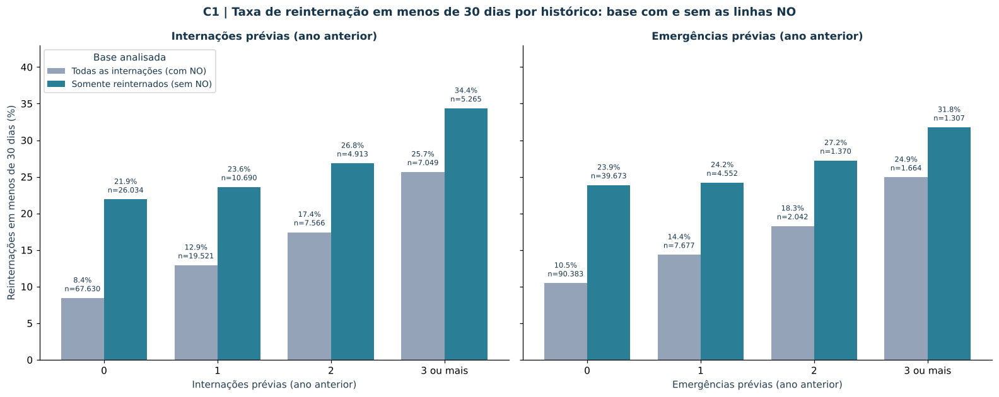

**O que mostra:** Taxa de reinternação em menos de 30 dias por grupo de histórico (0, 1, 2 e 3 ou mais), nas duas bases lado a lado: todas as internações (com NO) e somente reinternados (sem NO). O painel da esquerda mostra internações prévias e o da direita, emergências prévias.

**Interpretação:** O padrão se mantém nas duas bases: quanto maior o histórico, maior a taxa. Nas internações prévias, a taxa vai de 8,4% a 25,7% com NO e de 21,9% a 34,4% sem NO. Nas emergências, vai de 10,5% a 24,9% com NO e de 23,9% a 31,8% sem NO. A inclinação, porém, cai bastante. Com NO, o grupo de 3 ou mais tem uma taxa três vezes maior que o grupo sem histórico. Sem NO, a taxa é só 1,6 vez maior nas internações e 1,3 vez nas emergências, e os grupos 0 e 1 de emergência ficam quase iguais (23,9% e 24,2%). Boa parte do efeito do histórico está em separar quem volta de quem não volta: 42,8% do grupo >30 também teve internação prévia. Mesmo entre os que voltam, o histórico continua indicando quem volta mais cedo.

**Escolha visual:** Barras agrupadas com a mesma escala vertical nos dois painéis, para comparar diretamente a altura e a inclinação. Cinza para a base com NO, que é a referência, e azul-petróleo para o recorte. Cada barra mostra o percentual e o n, para que o leitor veja que os grupos sem NO são menores.

In [15]:
# [IA] Claude – comparação lado a lado: base principal (com "NO") × somente reinternados (sem "NO")
import io
import numpy as np
import matplotlib.pyplot as plt
from analise import rate_by

BASES_COMPARACAO = {
    "Todas as internações (com NO)": dados,
    "Somente reinternados (sem NO)": dados.loc[dados.readmitted.ne("NO")],
}
VARIAVEIS_HISTORICO = {
    "number_inpatient": "Internações prévias (ano anterior)",
    "number_emergency": "Emergências prévias (ano anterior)",
}
GRUPOS_HISTORICO = ["0", "1", "2", "3 ou mais"]

linhas = []
for nome_base, base in BASES_COMPARACAO.items():
    for variavel, rotulo in VARIAVEIS_HISTORICO.items():
        t = rate_by(base, variavel)
        t.insert(0, "variavel", rotulo)
        t.insert(0, "base", nome_base)
        linhas.append(t)
comparacao_bases = pd.concat(linhas, ignore_index=True)
comparacao_bases.to_csv(PROJECT / "out/parte_especifica/comparacao_bases_no.csv", index=False)

# Tabela: número de internações, casos <30 dias e taxa em %
display(comparacao_bases.drop(columns="taxa")
        .assign(percentual=lambda t: t.percentual.map(lambda v: f"{v:.2f}%")))

# Gráfico C1: barras agrupadas, mesma escala vertical nos dois painéis
CORES_BASE = {"Todas as internações (com NO)": "#94a3b8",
              "Somente reinternados (sem NO)": "#2a7f96"}
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), sharey=True)
largura = 0.38
for ax, (variavel, rotulo) in zip(axes, VARIAVEIS_HISTORICO.items()):
    sub = comparacao_bases.loc[comparacao_bases.variavel.eq(rotulo)]
    for k, (nome_base, cor) in enumerate(CORES_BASE.items()):
        d = sub.loc[sub.base.eq(nome_base)].set_index("grupo").reindex(GRUPOS_HISTORICO)
        x = np.arange(len(GRUPOS_HISTORICO)) + (k - 0.5) * largura
        ax.bar(x, d.percentual, width=largura, color=cor, label=nome_base)
        for xi, p, n in zip(x, d.percentual, d.n):
            ax.text(xi, p + 0.6, f"{p:.1f}%\nn={int(n):,}".replace(",", "."),
                    ha="center", va="bottom", fontsize=7.5)
    ax.set_xticks(range(len(GRUPOS_HISTORICO)), GRUPOS_HISTORICO)
    ax.set_title(rotulo, fontsize=11)
    ax.set_xlabel(rotulo)
    ax.set_ylim(0, comparacao_bases.percentual.max() * 1.25)
axes[0].set_ylabel("Reinternações em menos de 30 dias (%)")
axes[0].legend(title="Base analisada", loc="upper left", fontsize=9)
fig.suptitle("C1 | Taxa de reinternação em menos de 30 dias por histórico: base com e sem as linhas NO",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(PROJECT / "out/parte_especifica/figuras/C1.png", dpi=150, bbox_inches="tight")
# figuras.py usa o backend Agg, no qual plt.show() não exibe nada: mostra o PNG
png = io.BytesIO()
fig.savefig(png, format="png", dpi=110, bbox_inches="tight")
display(Image(data=png.getvalue()))
plt.close(fig)

nota = TG.C1_NOTA
display(Markdown("**O que mostra:** " + nota["o_que_mostra"] + "\n\n**Interpretação:** " + nota["interpretacao"] + "\n\n**Escolha visual:** " + nota["escolha_visual"]))


## 9. Storytelling, visualizações explanatórias e resposta à pesquisa

Esta seção junta o que a exploração mostrou em uma resposta direta à pergunta do grupo. As figuras X1 e X2 são explanatórias: foram desenhadas para comunicar um único contraste, a taxa de reinternação rápida subindo com o histórico. Elas trazem o percentual e o denominador em cada barra, a mesma escala vertical e um destaque de cor só no grupo de 3 ou mais. Abaixo estão o público, o percurso, a resposta, a mensagem central, as justificativas visuais e as limitações.

### Público-alvo

Gestores de qualidade hospitalar e analistas de dados que precisam decidir quais pacientes devem receber acompanhamento depois da alta. O texto evita jargão estatístico e sempre mostra o denominador de cada taxa.

### Percurso

O percurso segue a ordem da investigação. Primeiro verificamos se a base era confiável: duplicatas, ausências e extremos. Nessa etapa vimos que os "outliers" de histórico eram justamente o grupo de maior risco e decidimos preservá-los. Depois olhamos as distribuições (E1 a E3) e as correlações (E4), que mostraram que as variáveis do período da internação, como permanência, medicamentos e exames, quase não diferenciam os desfechos. A diferença apareceu no histórico de uso do hospital. Então comparamos as proporções por grupo de histórico (X1 e X2), cruzamos os dois históricos e a idade (M1 e M2), testamos a robustez em outras coortes e, por fim, repetimos a análise sem as linhas NO (C1).

### Resposta à pergunta

Sim, nas três partes da pergunta. (1) Separadamente: a taxa de reinternação em menos de 30 dias sobe de 8,4% para 25,7% conforme aumentam as internações prévias e de 10,5% para 24,9% conforme aumentam as emergências prévias. (2) Combinados: quem tem 3 ou mais internações e 3 ou mais emergências volta em 33,4% dos casos, quatro vezes mais que quem não tem nenhum dos dois históricos (8,3%). As internações prévias pesam mais que as emergências. (3) Só entre os reinternados: o padrão se mantém, mas mais fraco. As taxas vão de 21,9% a 34,4% por internações e de 23,9% a 31,8% por emergências. O histórico indica não só se o paciente volta, mas também se volta rápido. Para as internações prévias, o resultado também se sustenta com uma linha por paciente e sem as altas por óbito ou hospice: com 3 ou mais internações, a taxa fica entre 25,8% e 26,5%.

### Mensagem central

O passado hospitalar é o sinal mais claro de reinternação rápida nesta base. Um paciente que esteve internado três ou mais vezes no ano anterior tem cerca de uma chance em quatro de voltar antes de completar um mês da alta. Para quem não teve internação, a chance é de uma em doze. Essa informação já está disponível no momento da admissão.

### Justificativas visuais

Os gráficos E1 a E4 são exploratórios, usados para entender o comportamento dos dados, e X1 e X2 são explanatórios, usados para comunicar o achado. O X1 responde diretamente à pergunta de pesquisa. E1: o gráfico de barras empilhadas foi escolhido porque permite visualizar, simultaneamente, o volume total de internações em cada faixa etária e a composição interna de cada grupo segundo o desfecho de reinternação. E2: o tamanho da caixa revela em qual desfecho o tempo é mais previsível ou mais espalhado, comparando o padrão de quem volta após 30 dias ou quem volta antes de 30 dias. A única diferença visual ocorre na linha da mediana: quem não registra reinternação tem mediana de 3 dias, enquanto quem retorna (tanto após 30 dias quanto em menos de 30 dias) apresenta mediana ligeiramente maior, de 4 dias. E3: o histograma com a curva de densidade (KDE) é excelente para mostrar onde está o pico de consumo e a forma da distribuição, revelando a assimetria dos dados apresentados. Aplicado ao número de medicamentos diferentes administrados durante a internação, o gráfico mostra que, nos três cenários, os dados apresentam forte assimetria com cauda longa à direita e um pico concentrado na mesma faixa, entre 12 e 15 medicamentos. E4: o mapa de calor foi adotado porque permite visualizar simultaneamente todos os 28 pares possíveis entre as 8 variáveis analisadas, algo que seria ilegível em gráficos de dispersão individuais ou tabelas extensas. Além disso, a cor indica a força e o sinal da correlação, numa escala de −1 a 1. X1 e X2 usam barras com eixo começando em zero e a mesma escala vertical, para que a altura seja comparável entre os dois históricos. O laranja destaca só o grupo de 3 ou mais, que é a mensagem principal; os demais ficam em cinza (atributo pré-atentivo de cor). Cada barra traz o percentual e o n, para que o leitor não confunda um grupo pequeno com um grupo grande. M1 e M2 usam mapa de calor com escala fixa de 0 a 100% e o denominador em cada célula. O C1 coloca as duas bases lado a lado na mesma escala, para que a mudança de inclinação seja vista de imediato. Não foi necessário o uso de gráfico de pizza ou de radar.

### Limitações

Os resultados são descritivos e não provam causa: o histórico pode estar indicando gravidade ou condições crônicas que não estão na base. Um mesmo paciente pode aparecer em várias internações, e por isso não aplicamos testes de significância que suponham independência. NO significa ausência de registro de reinternação nesta rede de hospitais, e não garantia de que o paciente não voltou a outro serviço. Os dados são de 1999 a 2008, de hospitais dos Estados Unidos, e não devem ser generalizados para outros contextos sem cautela. Os grupos de 3 ou mais emergências e algumas células de M1 e M2 têm denominadores pequenos. Com uma linha por paciente, a taxa no grupo de 3 ou mais emergências cai de 24,9% para 16,1% (435 pacientes): o efeito das emergências depende mais de pacientes que se repetem na base do que o das internações.

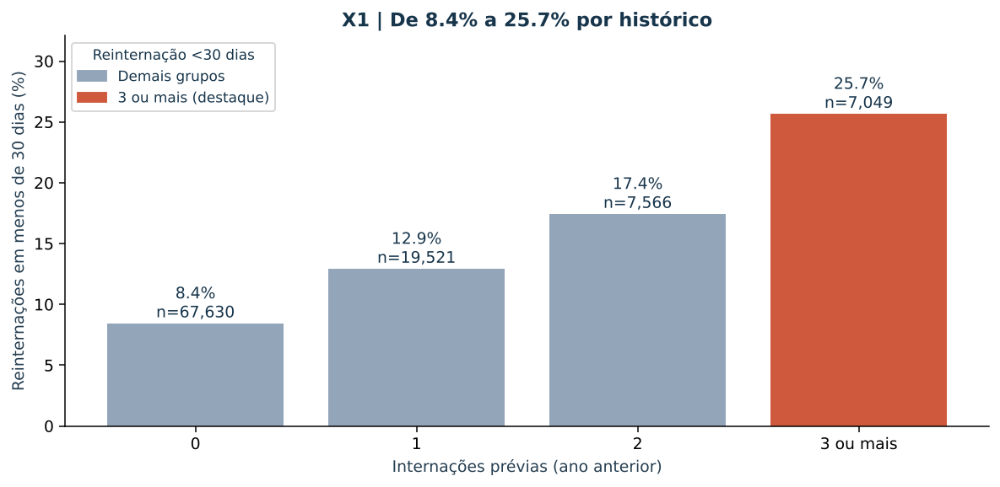

**O que mostra:** Porcentagem de internações que voltaram em menos de 30 dias em cada grupo de internações prévias no ano anterior (0, 1, 2, 3 ou mais), com o n de cada grupo acima da barra.

**Interpretação:** Na base integral: a taxa de reinternação em menos de 30 dias sobe a cada degrau do histórico de internações: 8,4% sem internação prévia, 12,9% com 1, 17,4% com 2 e 25,7% com 3 ou mais. O último grupo tem uma taxa três vezes maior que o primeiro (diferença de 17,2 pontos percentuais), com 7.049 internações no denominador.

**Escolha visual:** As barras começam em zero para que a altura seja proporcional à taxa. Só o grupo de 3 ou mais aparece em laranja, porque é a mensagem principal; os outros ficam em cinza. A escala vertical é a mesma do X2, para comparar os dois históricos.

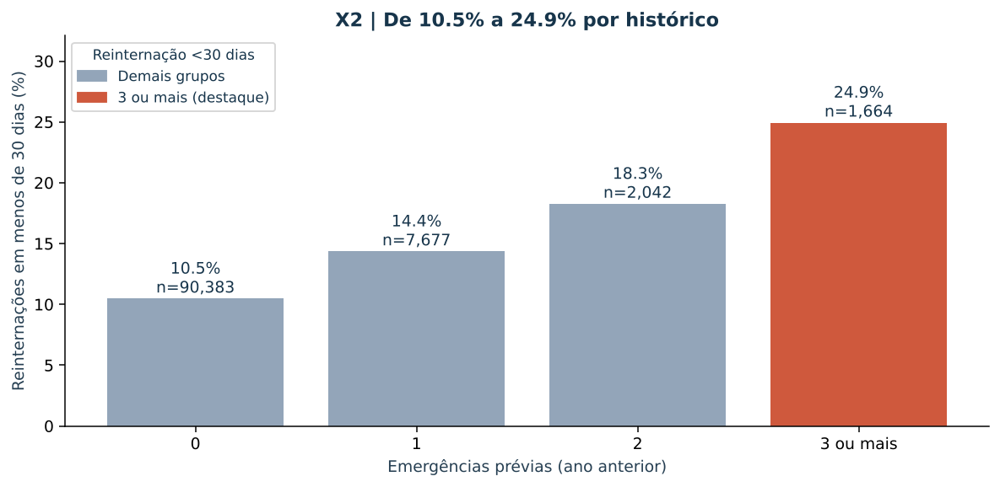

**O que mostra:** Porcentagem de internações que voltaram em menos de 30 dias em cada grupo de emergências prévias no ano anterior (0, 1, 2, 3 ou mais), com o n de cada grupo acima da barra.

**Interpretação:** Na base integral: o mesmo padrão aparece nas emergências: 10,5% sem emergência prévia, 14,4% com 1, 18,3% com 2 e 24,9% com 3 ou mais (diferença de 14,5 pontos). O grupo de 3 ou mais é pequeno (1.664 internações), e 88,8% da base não teve nenhuma emergência no ano anterior.

**Escolha visual:** Mesmo desenho do X1 (eixo em zero, destaque em laranja no 3 ou mais e mesma escala vertical), para que as duas figuras sejam lidas como um par.

In [16]:
# [IA] Claude – estrutura do storytelling com marcadores
from documentos import STORY_TITULOS
narrativa = story_text(dados)
for titulo, campo in STORY_TITULOS:
    display(Markdown("### " + titulo + "\n\n" + narrativa[campo]))
for chave in ["X1", "X2"]:
    display(Image(filename=str(figuras[chave]), width=850))
    exibir_nota(chave)


## Catálogo de requisitos, explicações e arquivos gerados

A tabela abaixo relaciona cada critério da Parte Específica ao lugar onde ele foi atendido: o arquivo, a figura ou a seção correspondente. Ela não estima nota; a avaliação cabe à docente. Depois da tabela vem o arquivo de explicações, com as decisões de tratamento dos dados, e a lista dos arquivos finais. O relatório PDF usa a base inteira; no dashboard é possível filtrar outros recortes e exportar dados e notas.

In [17]:
display(catalogo)
display(Markdown((PROJECT / "explicacao.md").read_text(encoding="utf-8")))
print("Arquivos finais no diretório do projeto:")
for nome in ["relatorio.pdf", "relatorio.md", "explicacao.md", "README.md"]:
    print(nome)


,id,criterio,evidencia,onde_encontrar,situacao
0,E01,Exploração - estrutura e tipos,estrutura_atributos.csv (50 atributos),Notebook: Estrutura; painel: Exploração > Estr...,Implementado no material; avaliação acadêmica ...
1,E02,Exploração - faltantes e cobertura,mecanismos_ausencia.csv; padroes_ausencia.csv,Notebook: Qualidade; painel: Qualidade,Implementado no material; avaliação acadêmica ...
2,E03,Exploração - inconsistências,auditoria_inconsistencias.csv (54 verificações),Notebook: Qualidade; relatório: Qualidade,Implementado no material; avaliação acadêmica ...
3,E04,Exploração - outliers,outliers_iqr.csv; figura Q2; extremos simultân...,Notebook e painel: Qualidade; relatório: Extremos,Implementado no material; avaliação acadêmica ...
4,E05,Exploração - mecanismo de ausência,Hipóteses por atributo; limites de MCAR/MAR/MNAR,Relatório: Ausências; explicações: decisões D0...,Implementado no material; avaliação acadêmica ...
5,E06,Exploração - tratamento justificado,"Preservação de linhas, categorias explícitas e...",Relatório: Qualidade; explicações: registro de...,Implementado no material; avaliação acadêmica ...
6,E07,Exploração - distribuições completas,descritiva_numerica.csv; frequencias_categoric...,Notebook: Distribuições; painel: seletor de at...,Implementado no material; avaliação acadêmica ...
7,E08,Exploração - relações com o desfecho,relacoes_com_alvo.csv (47 atributos); Pearson ...,Notebook: Relações; painel: Exploração > Relações,Implementado no material; avaliação acadêmica ...
8,E09,Exploração - relações multivariadas,M1: idade × histórico × alvo; M2: dois históri...,"Notebook, painel e relatório: Relações multiva...",Implementado no material; avaliação acadêmica ...
9,S01,Storytelling - pergunta e público,Gestores de qualidade e analistas; pergunta ex...,Notebook e painel: Pergunta e narrativa; relat...,Implementado no material; avaliação acadêmica ...


# Explicações do projeto e catálogo de requisitos

## 1. O que foi finalizado e onde localizar

O notebook reúne EDA executável com tabelas e gráficos, documentação das decisões, notas analíticas, narrativa da pesquisa e inicialização do Streamlit. O relatório PDF e sua versão Markdown usam a base integral. O dashboard permite recalcular o recorte e exportar dados e notas. Este material cobre a Parte Específica; não inclui a Parte Comum de K-Means sobre Obesity ou Wine Quality.

| id | criterio | evidencia | onde_encontrar | situacao |
| --- | --- | --- | --- | --- |
| E01 | Exploração - estrutura e tipos | estrutura_atributos.csv (50 atributos) | Notebook: Estrutura; painel: Exploração > Estrutura | Implementado no material; avaliação acadêmica cabe à docente. |
| E02 | Exploração - faltantes e cobertura | mecanismos_ausencia.csv; padroes_ausencia.csv | Notebook: Qualidade; painel: Qualidade | Implementado no material; avaliação acadêmica cabe à docente. |
| E03 | Exploração - inconsistências | auditoria_inconsistencias.csv (54 verificações) | Notebook: Qualidade; relatório: Qualidade | Implementado no material; avaliação acadêmica cabe à docente. |
| E04 | Exploração - outliers | outliers_iqr.csv; figura Q2; extremos simultâneos (medicamentos × internações prévias) | Notebook e painel: Qualidade; relatório: Extremos | Implementado no material; avaliação acadêmica cabe à docente. |
| E05 | Exploração - mecanismo de ausência | Hipóteses por atributo; limites de MCAR/MAR/MNAR | Relatório: Ausências; explicações: decisões D01-D04 | Implementado no material; avaliação acadêmica cabe à docente. |
| E06 | Exploração - tratamento justificado | Preservação de linhas, categorias explícitas e sensibilidades | Relatório: Qualidade; explicações: registro de decisões | Implementado no material; avaliação acadêmica cabe à docente. |
| E07 | Exploração - distribuições completas | descritiva_numerica.csv; frequencias_categoricas.csv; A1 e A2.1-A2.5 | Notebook: Distribuições; painel: seletor de atributos | Implementado no material; avaliação acadêmica cabe à docente. |
| E08 | Exploração - relações com o desfecho | relacoes_com_alvo.csv (47 atributos); Pearson e Spearman | Notebook: Relações; painel: Exploração > Relações | Implementado no material; avaliação acadêmica cabe à docente. |
| E09 | Exploração - relações multivariadas | M1: idade × histórico × alvo; M2: dois históricos × alvo | Notebook, painel e relatório: Relações multivariadas | Implementado no material; avaliação acadêmica cabe à docente. |
| S01 | Storytelling - pergunta e público | Gestores de qualidade e analistas; pergunta explícita | Notebook e painel: Pergunta e narrativa; relatório: Abertura | Implementado no material; avaliação acadêmica cabe à docente. |
| S02 | Storytelling - percurso e mensagem | Qualidade > distribuições > proporções > estratos > X1/X2 | Relatório: Storytelling; explicações: etapas 3-7 | Implementado no material; avaliação acadêmica cabe à docente. |
| S03 | Storytelling - resposta à pergunta | Proporções, diferença em pontos percentuais e limites | Painel: resposta do recorte; relatório: Resposta à pergunta | Implementado no material; avaliação acadêmica cabe à docente. |
| V01 | Visualizações - 4 exploratórias e 2 explanatórias | E1, E2, E3, E4; X1 e X2, com notas individuais | Notebook, relatório e painel | Implementado no material; avaliação acadêmica cabe à docente. |
| V02 | Visualizações - escolhas e atributos pré-atentivos | Justificativas por figura: posição, cor, escala, agregação | Notas analíticas; relatório: catálogo visual | Implementado no material; avaliação acadêmica cabe à docente. |
| V03 | Visualizações - títulos, eixos, legendas e escalas | Identificação explícita; eixos percentuais com zero; escalas compartilhadas | Figuras E1-E4 e X1-X2; testes de estrutura | Implementado no material; avaliação acadêmica cabe à docente. |
| V04 | Dashboard - organização e interação | Abas, filtros interligados, eixos configuráveis e exportação | src/parte_especifica/dashboard.py | Implementado no material; avaliação acadêmica cabe à docente. |
| N01 | Notas analíticas | O que mostra, interpretação e escolha visual por figura | notas_analiticas.json; relatório; painel: Notas e catálogo | Implementado no material; avaliação acadêmica cabe à docente. |
| N02 | Relatório analítico | Documento com método, evidências, gráficos e resposta à pergunta | relatorio.pdf e relatorio.md | Implementado no material; avaliação acadêmica cabe à docente. |
| R01 | Rastreabilidade e execução | Tabelas, SHA-256 da fonte, scripts, dependências e verificações | explicacao.md; resumo.json; validacao.json; README.md | Implementado no material; avaliação acadêmica cabe à docente. |

## 2. Arquivos e responsabilidades

- `src/parte_especifica/analise.py`: leitura, tipos semânticos, auditoria, faltantes, extremos, frequências, relações, estratos, sensibilidades e notas.
- `src/parte_especifica/figuras.py`: figuras estáticas reproduzíveis para notebook e relatório.
- `src/parte_especifica/documentos.py`: relatório PDF, relatório Markdown, README e esta explicação.
- `src/parte_especifica/dashboard.py`: filtros, abas, gráficos ao vivo, notas e exportação.
- `data/parte_especifica/`: CSVs originais.
- `out/parte_especifica/`: evidências em CSV, JSON e PNG.
- `relatorio.pdf` e `relatorio.md`: relatório analítico da base integral.
- `requirements.txt`: versões de dependências.
- `validacao.json`: resultado das verificações locais.
- `DATA_SOURCE.md`: referência e licença dos dados.

## 3. Ordem das etapas no Colab

1. Instalar dependências em Python 3.11 ou superior.
2. Restaurar o pacote incorporado e conferir seu SHA-256.
3. Ler os dados sem converter automaticamente None em ausente; executar a EDA e regenerar tabelas, gráficos e documentos.
4. Exibir estrutura e tipos.
5. Inspecionar qualidade, hipóteses de ausência e decisões de tratamento.
6. Analisar distribuições e valores extremos.
7. Analisar relações com o alvo, cruzamentos multivariados e sensibilidades.
8. Ler o storytelling e as seis visualizações principais, com suas notas.
9. Consultar o catálogo de requisitos.
10. Iniciar o Streamlit e exibir o painel dentro do notebook.

## 4. Estrutura e tipos de atributos

A base possui 101.766 linhas e 50 colunas: 2 identificadores, 8 medidas numéricas, 39 atributos categóricos explicativos e 1 alvo categórico. O catálogo lista todos os 50 atributos, dtype, tipo semântico, papel, cardinalidade, faltantes e exemplos. Identificadores não entram na correlação. Códigos de admissão e alta são nominais. Idade e peso são intervalos ordenados; diagnósticos são códigos textuais.

## 5. Qualidade, mecanismos e decisões justificadas

A auditoria não encontrou linhas inteiramente duplicadas nem encounter_id repetido: cada linha é uma internação única. Há 30.248 linhas de pacientes que já aparecem em outra internação (71.518 pacientes para 101.766 internações). Isso não é erro, é a própria estrutura da base, e por isso essas linhas foram mantidas. A repetição de pacientes é avaliada na análise de sensibilidade da seção 8. Os domínios numéricos estão dentro do esperado (permanência entre 1 e 14 dias, contagens inteiras e não negativas). Os códigos de diagnóstico com formato fora do padrão ICD-9 (2.646 em diag_1, 1.560 em diag_2 e 1.526 em diag_3) são códigos de 1 ou 2 dígitos, como "38" e "8", que parecem ter perdido o zero à esquerda ("038" é septicemia). Eles foram apenas sinalizados: o formato sozinho não permite afirmar que o diagnóstico esteja errado.

A base tem quatro tipos de informação faltante, e cada um foi tratado de forma diferente: o marcador "?" (falta de registro), a categoria Unknown/Invalid em gender (3 internações), os códigos administrativos que significam "sem informação" (por exemplo, admission_type_id 5, 6 e 8, que somam 10,2%) e o valor None nos exames de HbA1c e glicose. O None não é falta de dado: indica que o exame não foi feito. As ausências mais graves estão em weight (96,9%), medical_specialty (49,1%) e payer_code (39,6%). Em race (2,2%) e nos diagnósticos (até 1,4%) elas são pequenas.

weight (96,9%): Hipótese: o peso não era coletado de forma rotineira no sistema de origem. A falta depende do processo de registro, e não do paciente. A proporção de ausentes é quase igual nos três desfechos (95,8% a 97,6%) e em todas as faixas etárias, por isso a ausência pouco informa sobre a reinternação. Decisão: não imputar e não usar o peso como medida, porque restam só 3.197 registros com valor.

medical_specialty (49,1%): Hipótese: ausência dependente de outras variáveis (MAR). A falta cresce com a idade (17,4% de 0 a 10 anos e 52,3% de 80 a 90) e é um pouco menor entre quem não foi reinternado (47,3%, contra 50,9% em <30). Provavelmente reflete o tipo de admissão e a rotina de cada hospital. Decisão: manter as linhas e usar "Não informado" como categoria explícita, para não perder metade da base.

payer_code (39,6%): Hipótese: MAR ligado à idade e ao tipo de cobertura. A falta é de 91,3% entre 0 e 10 anos e cai para 28,4% acima de 90 anos, o que é coerente com a cobertura pública dos mais velhos (Medicare, código MC, é o pagador mais frequente da base). Quase não varia entre os desfechos (38,9% a 40,7%). Decisão: manter como "Não informado".

race (2,2%): Hipótese: falha de registro no cadastro. A falta é um pouco maior entre quem não foi reinternado (2,8%, contra 1,7% em <30). Como o volume é pequeno, a categoria "Não informado" foi mantida.

diag_1, diag_2 e diag_3 (0,02% a 1,4%): Hipótese: ausência estrutural. O diagnóstico secundário ou adicional falta quando o paciente teve menos diagnósticos registrados. O mapa de calor mostra que, das 358 internações sem diag_2, 279 também não têm diag_3. Decisão: manter e tratar como "Não informado", sem inventar diagnóstico.

A1Cresult (83,3%) e max_glu_serum (94,7%) = None: Não é ausência: o exame não foi feito, e isso tem significado clínico (é a pergunta do artigo original). Decisão: manter None como categoria própria.

Ausências conjuntas: Os mapas de calor mostram que as ausências não se concentram nas mesmas internações. Sem payer_code, 40,6% não têm especialidade, e com payer_code, 54,6% não têm. Isso afasta a ideia de um "bloco" de registros incompletos, que poderia ser excluído de uma só vez.

Os dados permitem verificar só se a falta muda com variáveis observadas (idade e desfecho). Não é possível provar MCAR, MAR ou MNAR, por isso as classificações acima são hipóteses. Em todos os casos, a decisão foi preservar as linhas, para não mudar a composição da base.

| id | situacao | decisao | justificativa |
| --- | --- | --- | --- |
| D01 | Ausências literais ? | Preservar linhas e usar Não informado nas categorias. | Evita exclusão de coortes com cobertura desigual; fonte original preservada. |
| D02 | Peso em intervalos e muito ausente | Não imputar valor pontual; não incluir no modelo demonstrativo. | Os intervalos não são uma medida exata e a cobertura não sustenta preenchimento numérico simples. |
| D03 | None em A1Cresult/max_glu_serum | Manter como não realizado. | A categoria possui significado de processo descrito na fonte [2]. |
| D04 | Códigos administrativos sem informação | Decodificar e separar das medidas numéricas. | Não há significado quantitativo para a média de códigos nominais. |
| D05 | Sexo Unknown/Invalid | Exibir Não informado; manter o registro. | Não inventa categoria e conserva rastreabilidade. |
| D06 | Repetição de paciente | Manter na base principal e comparar seleção de uma linha por paciente. | Várias internações do mesmo paciente não são duplicatas integrais. |
| D07 | Outliers por IQR | Preservar valores; documentar e comparar log1p. | Extremo não comprova erro e pode representar histórico relevante. |
| D08 | Categorias de alta cardinalidade | Agrupar Outras apenas no gráfico. | Melhora a leitura sem apagar categorias da tabela completa. |
| D09 | Grupos de histórico | 0, 1, 2 e 3 ou mais, com n e casos. | Reduz fragmentação e mantém uma ordem de leitura para comparação. |
| D10 | Óbito/hospice e representação por paciente | Disponibilizar análise de sensibilidade explícita. | Mostra efeitos da composição do denominador; não altera silenciosamente a base. |
| D11 | Correlação e estratos | Apresentar Pearson, Spearman, M1 e M2 sem alegar causalidade. | Controles observacionais disponíveis são limitados e há repetição de pacientes. |
| D12 | Modelo demonstrativo | Dividir por paciente e ajustar pré-processamento apenas no treino. | Reduz vazamento entre conjuntos; variáveis do período de internação não configuram previsão no momento da admissão. |

## 6. Detecção e avaliação de outliers

A regra do IQR sinaliza 45.358 ocorrências somando os oito atributos (a mesma internação pode ser contada mais de uma vez). Nas consultas ambulatoriais e nas emergências o IQR é zero, porque mais da metade das internações tem valor 0, e qualquer valor positivo vira "outlier" (16,4% e 11,2% das linhas). Em internações prévias o limite superior é 2,5. Assim, todo paciente com 3 ou mais internações seria sinalizado (6,9%), e esse é justamente o grupo com a maior taxa de reinternação em menos de 30 dias (25,7%). Remover esses casos apagaria o contraste que a pergunta quer estudar. Os valores também são plausíveis: a permanência fica entre 1 e 14 dias, e contagens altas de emergência correspondem a pacientes que usam muito o serviço. Decisão: preservar todos os valores e usar o IQR apenas como triagem.

Extremos simultâneos (medicamentos × internações prévias): Tabela cruzada e mapa de calor das internações que passam do limite superior do IQR em medicamentos (mais de 35) e em internações prévias (mais de 2,5, ou seja, 3 ou mais). Só 118 internações são extremas nas duas variáveis ao mesmo tempo. Os extremos não aparecem juntos. Entre as internações com muitos medicamentos, 4,6% também têm 3 ou mais internações prévias, contra 7,0% nas demais. Se os extremos fossem erro sistemático de digitação ou de carga, esperaríamos que se acumulassem nas mesmas linhas. Eles também se comportam de forma diferente em relação ao desfecho. A taxa de reinternação em menos de 30 dias é de 25,7% quando só o histórico é extremo, 11,5% quando só os medicamentos são extremos e 10,0% quando nenhum é. O histórico extremo carrega informação, por isso foi mantido.

| atributo | iqr | limite_inferior | limite_superior | sinalizados_iqr | sinalizados_pct |
| --- | --- | --- | --- | --- | --- |
| time_in_hospital | 4.000 | -4.000 | 12.000 | 2252 | 2.213 |
| num_lab_procedures | 26.000 | -8.000 | 96.000 | 143 | 0.141 |
| num_procedures | 2.000 | -3.000 | 5.000 | 4954 | 4.868 |
| num_medications | 10.000 | -5.000 | 35.000 | 2557 | 2.513 |
| number_outpatient | 0.000 | 0.000 | 0.000 | 16739 | 16.449 |
| number_emergency | 0.000 | 0.000 | 0.000 | 11383 | 11.185 |
| number_inpatient | 1.000 | -1.500 | 2.500 | 7049 | 6.927 |
| number_diagnoses | 3.000 | 1.500 | 13.500 | 281 | 0.276 |

## 7. Distribuições e relações multivariadas

As distribuições mostram uma base concentrada em pacientes idosos (47,7% entre 60 e 80 anos) e mulheres (53,8%), com internações curtas (mediana de 4 dias) e cerca de 15 medicamentos. As contagens de histórico têm muitos zeros. Nas variáveis categóricas, a maior parte dos 23 medicamentos quase não varia (mais de 99% "No" em vários deles, e examide e citoglipton têm uma única categoria). Os exames HbA1c e glicose quase sempre aparecem como "não realizados". O desfecho se divide em 53,9% NO, 34,9% >30 e 11,2% <30: a classe de interesse é minoritária, por isso comparamos proporções e não contagens absolutas.

Emergências prévias (skewness 22,86 e kurtosis 1.191,7): a distribuição mais extrema da base. 88,8% das internações têm zero emergências, e poucos pacientes chegam a dezenas (máximo de 76). A média (0,20) não representa o paciente típico.

Consultas ambulatoriais prévias (skewness 8,83 e kurtosis 147,9): mesmo padrão: 83,6% de zeros e uma cauda longa à direita (máximo de 42).

Internações prévias (skewness 3,61 e kurtosis 20,7): assimetria forte, mas menor. 66,5% não tiveram internação no ano anterior, e a cauda chega a 21. É a variável central da pergunta, por isso foi agrupada em 0, 1, 2 e 3 ou mais.

Medicamentos (skewness 1,33 e kurtosis 3,47): assimetria moderada à direita, com mediana de 15 e alguns casos acima de 35.

Permanência e procedimentos (skewness 1,13 e 1,32; kurtosis 0,85 e 0,86): assimetria moderada e caudas leves. Os valores são limitados pelo próprio domínio (1 a 14 dias e 0 a 6 procedimentos).

Exames laboratoriais (skewness -0,24 e kurtosis -0,25): quase simétrica, com média (43,1) e mediana (44) próximas.

Diagnósticos (skewness -0,88 e kurtosis -0,08): assimetria à esquerda: os valores se acumulam no teto de 9 diagnósticos (48,6% das internações), e só 0,1% passa disso.

A kurtosis apresentada é o excesso de curtose (o valor da normal é 0). Nas três contagens de histórico, a média é puxada pela cauda, então descrevemos essas variáveis por mediana, percentis e grupos. Os coeficientes de Spearman foram mantidos ao lado dos de Pearson porque não dependem da forma da distribuição.

O catálogo de relações inclui os 47 atributos originais que não são IDs nem o próprio alvo. Para medidas numéricas, há médias e medianas por desfecho; para categorias, contagens e proporções <30 dias. Pearson e Spearman são calculados separadamente. M1 cruza idade, histórico de internações e desfecho; M2 cruza internações prévias, emergências prévias e desfecho. Cada célula tem denominador e numerador exportados. A apresentação é descritiva, sem equiparar correlação, estratificação ou associação a efeito causal.

A comparação inclui quatro coortes: todas as internações; uma linha por paciente pelo menor encounter_id; exclusão de altas por óbito/hospice (códigos 11, 13, 14, 19, 20 e 21); e a combinação das duas escolhas. A base integral é o ponto de partida, e os outros recortes mostram a dependência dos resultados das decisões de seleção. Não se afirma que a seleção pelo ID reconstrua a primeira internação em ordem temporal nem que reproduza exatamente a coorte do artigo.

## 8. Pergunta, público-alvo e storytelling

Quanto mais vezes o paciente foi internado no ano anterior, e quanto mais vezes foi à emergência, maior a chance de voltar ao hospital em menos de 30 dias? Isso vale para cada um separadamente e para os dois combinados? E o padrão se mantém quando olhamos só os pacientes que foram reinternados em algum momento?

1. Quanto maior o número de internações no ano anterior (0, 1, 2, 3 ou mais), maior a taxa de reinternação em menos de 30 dias? E quanto maior o número de idas à emergência? (X1 e X2)
2. Quando o paciente tem as duas coisas ao mesmo tempo, internações e emergências, o risco é ainda maior? (M2)
3. Esses padrões se mantêm quando olhamos apenas os pacientes que foram reinternados em algum momento (sem as linhas NO)? (C1)

A base principal segue o artigo original: compara quem voltou em menos de 30 dias com todos os demais, que reúnem quem voltou depois de 30 dias (>30) e quem não tem reinternação registrada (NO). Para responder à terceira parte da pergunta, refizemos as taxas só com os pacientes que voltaram ao hospital em algum momento, retirando as linhas NO. Nessa base de 46.902 internações, a pergunta passa a ser: entre quem volta, quem volta mais rápido? A taxa geral sobe para 24,2%, porque o denominador fica menor. Por isso, o que interessa comparar é a inclinação entre os grupos, e não o nível das barras.

O padrão se mantém nas duas bases: quanto maior o histórico, maior a taxa. Nas internações prévias, a taxa vai de 8,4% a 25,7% com NO e de 21,9% a 34,4% sem NO. Nas emergências, vai de 10,5% a 24,9% com NO e de 23,9% a 31,8% sem NO. A inclinação, porém, cai bastante. Com NO, o grupo de 3 ou mais tem uma taxa três vezes maior que o grupo sem histórico. Sem NO, a taxa é só 1,6 vez maior nas internações e 1,3 vez nas emergências, e os grupos 0 e 1 de emergência ficam quase iguais (23,9% e 24,2%). Boa parte do efeito do histórico está em separar quem volta de quem não volta: 42,8% do grupo >30 também teve internação prévia. Mesmo entre os que voltam, o histórico continua indicando quem volta mais cedo.

Gestores de qualidade hospitalar e analistas de dados que precisam decidir quais pacientes devem receber acompanhamento depois da alta. O texto evita jargão estatístico e sempre mostra o denominador de cada taxa.

O percurso segue a ordem da investigação. Primeiro verificamos se a base era confiável: duplicatas, ausências e extremos. Nessa etapa vimos que os "outliers" de histórico eram justamente o grupo de maior risco e decidimos preservá-los. Depois olhamos as distribuições (E1 a E3) e as correlações (E4), que mostraram que as variáveis do período da internação, como permanência, medicamentos e exames, quase não diferenciam os desfechos. A diferença apareceu no histórico de uso do hospital. Então comparamos as proporções por grupo de histórico (X1 e X2), cruzamos os dois históricos e a idade (M1 e M2), testamos a robustez em outras coortes e, por fim, repetimos a análise sem as linhas NO (C1).

Sim, nas três partes da pergunta. (1) Separadamente: a taxa de reinternação em menos de 30 dias sobe de 8,4% para 25,7% conforme aumentam as internações prévias e de 10,5% para 24,9% conforme aumentam as emergências prévias. (2) Combinados: quem tem 3 ou mais internações e 3 ou mais emergências volta em 33,4% dos casos, quatro vezes mais que quem não tem nenhum dos dois históricos (8,3%). As internações prévias pesam mais que as emergências. (3) Só entre os reinternados: o padrão se mantém, mas mais fraco. As taxas vão de 21,9% a 34,4% por internações e de 23,9% a 31,8% por emergências. O histórico indica não só se o paciente volta, mas também se volta rápido. Para as internações prévias, o resultado também se sustenta com uma linha por paciente e sem as altas por óbito ou hospice: com 3 ou mais internações, a taxa fica entre 25,8% e 26,5%.

O passado hospitalar é o sinal mais claro de reinternação rápida nesta base. Um paciente que esteve internado três ou mais vezes no ano anterior tem cerca de uma chance em quatro de voltar antes de completar um mês da alta. Para quem não teve internação, a chance é de uma em doze. Essa informação já está disponível no momento da admissão.

Os gráficos E1 a E4 são exploratórios, usados para entender o comportamento dos dados, e X1 e X2 são explanatórios, usados para comunicar o achado. O X1 responde diretamente à pergunta de pesquisa. E1: o gráfico de barras empilhadas foi escolhido porque permite visualizar, simultaneamente, o volume total de internações em cada faixa etária e a composição interna de cada grupo segundo o desfecho de reinternação. E2: o tamanho da caixa revela em qual desfecho o tempo é mais previsível ou mais espalhado, comparando o padrão de quem volta após 30 dias ou quem volta antes de 30 dias. A única diferença visual ocorre na linha da mediana: quem não registra reinternação tem mediana de 3 dias, enquanto quem retorna (tanto após 30 dias quanto em menos de 30 dias) apresenta mediana ligeiramente maior, de 4 dias. E3: o histograma com a curva de densidade (KDE) é excelente para mostrar onde está o pico de consumo e a forma da distribuição, revelando a assimetria dos dados apresentados. Aplicado ao número de medicamentos diferentes administrados durante a internação, o gráfico mostra que, nos três cenários, os dados apresentam forte assimetria com cauda longa à direita e um pico concentrado na mesma faixa, entre 12 e 15 medicamentos. E4: o mapa de calor foi adotado porque permite visualizar simultaneamente todos os 28 pares possíveis entre as 8 variáveis analisadas, algo que seria ilegível em gráficos de dispersão individuais ou tabelas extensas. Além disso, a cor indica a força e o sinal da correlação, numa escala de −1 a 1. X1 e X2 usam barras com eixo começando em zero e a mesma escala vertical, para que a altura seja comparável entre os dois históricos. O laranja destaca só o grupo de 3 ou mais, que é a mensagem principal; os demais ficam em cinza (atributo pré-atentivo de cor). Cada barra traz o percentual e o n, para que o leitor não confunda um grupo pequeno com um grupo grande. M1 e M2 usam mapa de calor com escala fixa de 0 a 100% e o denominador em cada célula. O C1 coloca as duas bases lado a lado na mesma escala, para que a mudança de inclinação seja vista de imediato. Não foi necessário o uso de gráfico de pizza ou de radar.

## 9. Notas analíticas catalogadas por visualização

### E1 - Distribuição etária

**O que mostra:** Número de internações por faixa etária de dez anos, com a parte de reinternações em menos de 30 dias empilhada em laranja.

**Interpretação:** A base é de pacientes mais velhos: 25,6% das internações estão entre 70 e 80 anos e 81,6% entre 50 e 90. A fatia laranja acompanha o tamanho de cada faixa. A taxa fica entre 9,7% e 12,1% dos 30 aos 100 anos, com pico de 14,2% entre 20 e 30 anos, uma faixa pequena (1.657 internações). A idade, sozinha, não separa bem quem volta rápido.

**Escolha visual:** Barras empilhadas em duas cores mostram o volume de cada faixa e, ao mesmo tempo, a parte que volta em menos de 30 dias. O eixo x segue a ordem natural das faixas, e o laranja é a cor do desfecho de interesse em todo o projeto.

### E2 - Permanência por desfecho

**O que mostra:** Boxplot da permanência hospitalar em dias para cada desfecho: sem reinternação registrada, após 30 dias e em menos de 30 dias.

**Interpretação:** As medianas são quase iguais: 4 dias para <30 e >30 e 3 dias para quem não foi reinternado. As caixas se sobrepõem bastante. A média é um pouco maior em <30 (4,77 dias, contra 4,35 nas demais). A permanência tem relação fraca com a reinternação rápida e não diferencia os grupos tão bem quanto o histórico.

**Escolha visual:** Os três boxplots ficam lado a lado e na mesma escala, para comparar mediana e dispersão. Cada caixa usa a cor do seu desfecho, a mesma dos outros gráficos.

### E3 - Medicamentos por internação

**O que mostra:** Distribuição do número de medicamentos por internação em três painéis, um por desfecho, com a curva de densidade (KDE) em vermelho na escala de contagem.

**Interpretação:** As três distribuições têm a mesma forma: assimétricas à direita, com pico entre 10 e 20 medicamentos e cauda até cerca de 80. A mediana sobe pouco de NO (14) para >30 (15) e <30 (16). Como as alturas refletem o tamanho de cada grupo, o que importa comparar é a forma, e ela quase não muda.

**Escolha visual:** Um painel por desfecho evita sobrepor barras de grupos com tamanhos muito diferentes. A cor de cada painel é a cor do desfecho, e a KDE em vermelho contrasta com as barras para destacar a forma. O eixo x é o mesmo (0 a 85) nos três painéis.

### E4 - Correlações por classe do desfecho

**O que mostra:** Quatro matrizes de correlação entre as oito variáveis numéricas: Pearson e Spearman, calculadas separadamente para <30 dias e para as demais categorias.

**Interpretação:** Nenhuma correlação é forte. A maior é entre permanência e medicamentos (0,46 a 0,48). A diferença mais interessante está entre internações e emergências prévias: a correlação é de 0,32 (Pearson) no grupo <30 e de 0,24 nas demais. Entre quem volta rápido, os dois históricos andam mais juntos, o que motivou o cruzamento M2. Pearson e Spearman dão resultados parecidos, então as conclusões não dependem dos extremos.

**Escolha visual:** Mapa de calor com escala divergente fixa de -1 a 1 (azul negativo, vermelho positivo), igual nos quatro painéis, para que as cores sejam comparáveis. Os valores aparecem em cada célula, porque as diferenças são pequenas.

### M1 - Idade, histórico e desfecho

**O que mostra:** Mapa de calor em que as linhas são faixas etárias e as colunas são grupos de internações prévias (0, 1, 2, 3 ou mais). Cada célula mostra a porcentagem de reinternação em menos de 30 dias e o número de internações (n).

**Interpretação:** Na base integral: em quase todas as faixas etárias, a taxa sobe da esquerda para a direita, de 0 até 3 ou mais internações prévias. Entre 70 e 80 anos, por exemplo, vai de 9,6% para 23,5%. O efeito do histórico não é explicado pela idade. As células mais escuras (41,6% entre 20 e 30 anos com 3 ou mais) têm denominadores pequenos e devem ser lidas com cautela.

**Escolha visual:** A escala de cor é fixa de 0 a 100%, para que a mesma cor signifique a mesma taxa em qualquer recorte. O n aparece em cada célula para que uma célula escura com poucos casos não seja lida como resultado forte.

### M2 - Dois históricos simultâneos

**O que mostra:** Mapa de calor em que as linhas são os grupos de internações prévias e as colunas os grupos de emergências prévias. Cada célula mostra a porcentagem de reinternação em menos de 30 dias e o n.

**Interpretação:** Na base integral: os dois históricos somam risco. Quem não teve internação nem emergência no ano anterior volta em menos de 30 dias em 8,3% dos casos. Com 3 ou mais internações e 3 ou mais emergências, a taxa é de 33,4% (n=752), quatro vezes maior. As internações prévias pesam mais: sem nenhuma emergência, a taxa já vai de 8,3% para 23,4% quando as internações passam de 0 para 3 ou mais. As emergências acrescentam um efeito menor e menos regular (na linha de 2 internações, a taxa oscila entre 15,2% e 20,5%).

**Escolha visual:** Usamos o mesmo formato e a mesma escala fixa do M1. Cruzar os dois históricos numa única grade permite ver se o risco aumenta quando o paciente tem os dois ao mesmo tempo. O n em cada célula indica onde os grupos são pequenos.

### I1 - Exploração interativa

**O que mostra:** Gráfico de dispersão de duas variáveis numéricas escolhidas no painel, com cor por desfecho. Usa uma amostra de até 4.000 internações.

**Interpretação:** O gráfico serve para o leitor formular as próprias perguntas no painel. Na maioria dos pares de variáveis, as cores dos desfechos se misturam, o que confirma que nenhuma variável numérica, sozinha, separa quem volta em menos de 30 dias.

**Escolha visual:** Os pontos são semitransparentes para que as áreas com muitas internações apareçam mais escuras. Os eixos podem ser escolhidos no painel para que o leitor teste outras combinações.

### A1 - Distribuição acumulada (ECDF) das variáveis numéricas

**O que mostra:** Distribuição acumulada empírica (ECDF) das oito variáveis numéricas: para cada valor, a proporção de internações com valor menor ou igual a ele.

**Interpretação:** As curvas de histórico sobem quase até o topo no zero: 66,5% das internações não tiveram internação prévia, 88,8% não tiveram emergência e 83,6% não tiveram consulta ambulatorial. Medicamentos e exames sobem de forma gradual. Cerca de 76% das internações usam até 20 medicamentos.

**Escolha visual:** A ECDF mostra a distribuição inteira sem escolher número de classes e permite ler percentis diretamente no eixo y. Uma curva por painel evita misturar escalas diferentes.

### A2 - Distribuições categóricas completas

**O que mostra:** Frequência de todas as 40 variáveis categóricas (incluindo o desfecho), distribuídas em cinco páginas.

**Interpretação:** Muitas variáveis de medicamento são quase constantes, e várias categóricas são dominadas por uma única categoria ou por "Não informado". Essas variáveis dão pouca informação para separar os desfechos. As categorias raras, com poucos registros, também seriam um problema para um modelo de machine learning: ele veria poucos exemplos delas e tenderia a aprender ruído. Numa modelagem futura, o caminho seria agrupar as categorias raras em "Outras" e descartar as variáveis quase constantes.

**Escolha visual:** Barras verticais com as sete categorias mais frequentes e o restante agregado em "Outras", só na apresentação. A tabela completa fica no CSV.

### H1 - Histogramas numéricos por desfecho - parte 1

**O que mostra:** Histogramas de permanência, exames laboratoriais, procedimentos e medicamentos, com um painel para cada desfecho.

**Interpretação:** As formas são parecidas nos três desfechos. As diferenças de altura vêm principalmente do tamanho dos grupos (NO é cerca de cinco vezes maior que <30). Nenhuma dessas quatro variáveis do período da internação mostra um deslocamento claro no grupo <30.

**Escolha visual:** Grade de linhas (variáveis) por colunas (desfechos), com eixo x compartilhado em cada linha. Assim, a comparação entre desfechos é feita na mesma escala horizontal. As cores são as mesmas dos demais gráficos.

### H2 - Histogramas numéricos por desfecho - parte 2

**O que mostra:** Histogramas de consultas ambulatoriais, emergências, internações prévias e diagnósticos, com um painel para cada desfecho.

**Interpretação:** As três contagens de histórico se concentram no zero, mas a cauda das internações prévias é proporcionalmente mais pesada em <30: 49,8% desse grupo teve ao menos uma internação no ano anterior, contra 24,2% em NO. Os diagnósticos se acumulam no valor 9 em todos os desfechos.

**Escolha visual:** Mesma grade do H1, para manter a leitura consistente. Barras espaçadas deixam claro que as variáveis são contagens discretas.

### Q1 - Registros faltantes por atributo

**O que mostra:** Contagem de registros faltantes por atributo, separada por tipo: marcador "?", Unknown/Invalid, código administrativo sem informação e None nos exames.

**Interpretação:** O peso falta em quase toda a base (98.569 registros). Especialidade e pagador faltam em cerca de metade e 40% das internações. O None de HbA1c e glicose é o segundo maior volume, mas significa exame não feito, e não dado perdido. Os demais faltantes são pequenos.

**Escolha visual:** Barras horizontais ordenadas da maior para a menor, para ler os nomes dos atributos sem girar o texto. A ordenação cria uma hierarquia visual: o olho começa pelo atributo mais crítico (weight, que falta em quase toda a base) e desce até os menores, sem precisar comparar barras espalhadas. A cor separa o tipo de faltante, porque cada tipo recebe tratamento diferente. Os rótulos trazem a contagem exata.

### Q2 - Valores extremos

**O que mostra:** Um boxplot para cada uma das oito variáveis numéricas, usando todas as internações. Os pontos isolados são os valores além dos limites do IQR.

**Interpretação:** Em consultas ambulatoriais, emergências e internações prévias, quase todos os pontos acima da caixa são contagens plausíveis de uso do serviço, e não erros. Nas emergências, a caixa vira uma linha no zero. Permanência e procedimentos ficam presos aos limites do domínio. Exames laboratoriais têm alguns valores acima de 96, mas são poucos (0,14%).

**Escolha visual:** Escolhemos o boxplot porque ele mostra diretamente a mediana, os quartis e os pontos que a regra do IQR sinaliza. Cada variável tem seu próprio painel e sua própria escala, porque os intervalos são muito diferentes (0 a 6 procedimentos e até 132 exames).

### X1 - Reinternação e internações prévias

**O que mostra:** Porcentagem de internações que voltaram em menos de 30 dias em cada grupo de internações prévias no ano anterior (0, 1, 2, 3 ou mais), com o n de cada grupo acima da barra.

**Interpretação:** Na base integral: a taxa de reinternação em menos de 30 dias sobe a cada degrau do histórico de internações: 8,4% sem internação prévia, 12,9% com 1, 17,4% com 2 e 25,7% com 3 ou mais. O último grupo tem uma taxa três vezes maior que o primeiro (diferença de 17,2 pontos percentuais), com 7.049 internações no denominador.

**Escolha visual:** As barras começam em zero para que a altura seja proporcional à taxa. Só o grupo de 3 ou mais aparece em laranja, porque é a mensagem principal; os outros ficam em cinza. A escala vertical é a mesma do X2, para comparar os dois históricos.

### X2 - Reinternação e emergências prévias

**O que mostra:** Porcentagem de internações que voltaram em menos de 30 dias em cada grupo de emergências prévias no ano anterior (0, 1, 2, 3 ou mais), com o n de cada grupo acima da barra.

**Interpretação:** Na base integral: o mesmo padrão aparece nas emergências: 10,5% sem emergência prévia, 14,4% com 1, 18,3% com 2 e 24,9% com 3 ou mais (diferença de 14,5 pontos). O grupo de 3 ou mais é pequeno (1.664 internações), e 88,8% da base não teve nenhuma emergência no ano anterior.

**Escolha visual:** Mesmo desenho do X1 (eixo em zero, destaque em laranja no 3 ou mais e mesma escala vertical), para que as duas figuras sejam lidas como um par.

### A2_1 - Distribuições categóricas - página 1

**O que mostra:** Frequências de race, gender, age, weight, admission_type_id, discharge_disposition_id, admission_source_id e payer_code.

**Interpretação:** Predominam pacientes Caucasian (74,8%) e mulheres (53,8%). O peso é "Não informado" em 96,9% dos casos. A admissão de emergência (código 1) responde por 53,1% e a alta para casa (código 1) por 59,2%. Em payer_code, "Não informado" (39,6%) supera o Medicare (31,9%).

**Escolha visual:** Barras verticais ordenadas por frequência. Os códigos administrativos aparecem como categorias, e não como números, porque são nominais.

### A2_2 - Distribuições categóricas - página 2

**O que mostra:** Frequências de medical_specialty, diag_1, diag_2, diag_3, max_glu_serum, A1Cresult, metformin e repaglinide.

**Interpretação:** A especialidade mais comum é "Não informado" (49,1%), seguida de medicina interna (14,4%). Os diagnósticos têm centenas de códigos, e o mais frequente (428, insuficiência cardíaca) não passa de 7%. Glicose e HbA1c não foram medidas em 94,7% e 83,3% das internações. A metformina é usada em cerca de 20%.

**Escolha visual:** A agregação em "Outras" é necessária para os diagnósticos, com mais de 700 códigos cada. Sem ela o gráfico ficaria ilegível.

### A2_3 - Distribuições categóricas - página 3

**O que mostra:** Frequências de nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide e pioglitazone.

**Interpretação:** Quase todos os registros são "No". Glipizide (11,2% Steady) e glyburide (9,1%) são os mais usados nesta página. Acetohexamide e tolbutamide praticamente não aparecem.

**Escolha visual:** Mesmo formato das outras páginas, para facilitar a comparação. O eixo y em contagem deixa evidente a dominância do "No".

### A2_4 - Distribuições categóricas - página 4

**O que mostra:** Frequências de rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton e insulin.

**Interpretação:** A insulina é a exceção: só 46,6% "No", com 30,3% Steady, 12,0% Down e 11,1% Up. Examide e citoglipton têm uma única categoria em toda a base, e as outras ficam próximas de 100% "No".

**Escolha visual:** Mesmo formato das outras páginas. Variáveis constantes foram mantidas no gráfico, para documentar que foram verificadas.

### A2_5 - Distribuições categóricas - página 5

**O que mostra:** Frequências das combinações de medicamentos, de change, de diabetesMed e do desfecho readmitted.

**Interpretação:** As combinações são raríssimas. Houve mudança na medicação de diabetes em 46,2% das internações, e 77,0% receberam algum medicamento para diabetes. O desfecho se divide em 53,9% NO, 34,9% >30 e 11,2% <30.

**Escolha visual:** Mesmo formato das outras páginas. A página termina com o desfecho, que serve de referência para todas as proporções do projeto.

## 10. Interface e comportamento dos filtros

As abas separam Exploração, Pergunta e narrativa, Qualidade, Notas e catálogo e Classificação. Os filtros de idade, sexo, insulina e permanência afetam os seis gráficos principais e a narrativa. Há sensibilidades opcionais de uma linha por paciente e exclusão de altas por óbito/hospice. A auditoria de qualidade usa explicitamente a base integral, inclusive a figura Q2. O seletor de atributos cobre todas as variáveis analíticas. A dispersão usa até 4.000 pontos para manter resposta rápida; indicadores e seis gráficos principais usam o recorte inteiro. Filtros sem resultados mostram mensagem em vez de causar exceção.

## 11. Modelo de classificação: papel e limites

A regressão logística é opcional e usa a base completa, como indicado na interface. GroupShuffleSplit separa pacientes com semente 42 e fração de teste de 20%. A imputação e a padronização numéricas e a codificação categórica são ajustadas apenas no treino. IDs e rótulo não entram como preditores. Há acurácia, precisão, recall, ROC AUC e matriz de confusão. Pesos de classe balanceados e limiar 0,5 são explícitos. O modelo não substitui a EDA ou a Parte Comum e não representa validação clínica prospectiva.

## 12. Execução no Colab e exportação

Executar tudo instala dependências, restaura dados e código e apresenta a EDA. A última célula inicia o Streamlit como subprocesso, verifica /_stcore/health e usa google.colab.output.serve_kernel_port_as_iframe. O endereço localhost do computador pessoal não aponta para o servidor remoto. O iframe depende de sessão autenticada e runtime conectado. A célula pode ser reexecutada e encerra somente o processo anterior que ela mesma iniciou. CORS e proteção XSRF permanecem habilitados. O notebook contém os dados, sem exigir upload de CSV, montagem de Drive ou chave de túnel. O PDF já incluído pode ser baixado; o recorte CSV e as notas podem ser exportados pelo painel.

## 13. Verificações e critérios de conclusão

As verificações incluem integridade da base, catálogo de 50 atributos, cobertura de 47 relações com o alvo, consistência de numeradores e denominadores, tratamento do marcador None, casos com filtros vazios, construção dos gráficos, separação de pacientes no modelo e execução das células de EDA. O registro validacao.json contém os resultados efetivamente obtidos. A abertura e a execução dentro de uma conta Google dependem da autenticação no Colab e não são inferidas dos testes locais. Não se atribui pontuação automaticamente: o catálogo comprova material disponível para avaliação da docente.

## 14. Limitações e referências

Os resultados são descritivos e não provam causa: o histórico pode estar indicando gravidade ou condições crônicas que não estão na base. Um mesmo paciente pode aparecer em várias internações, e por isso não aplicamos testes de significância que suponham independência. NO significa ausência de registro de reinternação nesta rede de hospitais, e não garantia de que o paciente não voltou a outro serviço. Os dados são de 1999 a 2008, de hospitais dos Estados Unidos, e não devem ser generalizados para outros contextos sem cautela. Os grupos de 3 ou mais emergências e algumas células de M1 e M2 têm denominadores pequenos. Com uma linha por paciente, a taxa no grupo de 3 ou mais emergências cai de 24,9% para 16,1% (435 pacientes): o efeito das emergências depende mais de pacientes que se repetem na base do que o das internações.

[1] UCI, Diabetes 130-US Hospitals for Years 1999-2008. DOI 10.24432/C5230J. https://archive.ics.uci.edu/dataset/296/diabetes-130-us-hospitals-for-years-1999-2008

[2] Strack et al., 2014. DOI 10.1155/2014/781670. https://pmc.ncbi.nlm.nih.gov/articles/PMC3996476/

[3] API do Colab: https://github.com/googlecolab/colabtools/blob/main/google/colab/output/_util.py

[4] Streamlit: https://docs.streamlit.io/develop/api-reference/configuration/config.toml


Arquivos finais no diretório do projeto:
relatorio.pdf
relatorio.md
explicacao.md
README.md


## Declaração de uso de IA

Ferramenta utilizada: Claude (Anthropic), usado como assistente de código e de redação. O que foi gerado com IA na Parte Específica: (1) os trechos de código marcados com "[IA] Claude": tabelas auxiliares, ajustes de gráficos, heatmaps de ausência, extremos simultâneos e a comparação C1; (2) a redação dos textos analíticos (src/parte_especifica/textos_grupo.py), incluindo as notas de cada gráfico. O grupo revisou os textos e conferiu os números citados. O que foi decidido e feito pelo grupo: o dataset original tratava do absenteísmo no trabalho. No entanto, a professora reenviou o e-mail a um dos membros, detalhando alguns problemas que o dataset poderia apresentar, como o pequeno número de pessoas, o que resultaria em variáveis repetidas em várias instâncias. Diante disso, outro membro sugeriu um dataset substituto, sobre diabetes. As perguntas foram formuladas de modo a não seguir um único caminho: a análise segue direções diferentes conforme os valores encontrados e as condições necessárias para chegar a cada resultado. Verificação: todos os números citados podem ser reproduzidos executando o notebook. O grupo revisou os resultados e se responsabiliza pelo conteúdo entregue. Todos os integrantes sabem explicar cada parte do trabalho. A declaração completa, que também cobre a Parte Comum e traz as assinaturas, está em docs/DECLARACAO_IA.pdf.

## Referências e abertura do dashboard

- [1] Clore, J.; Cios, K.; DeShazo, J.; Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999-2008*. UCI Machine Learning Repository. DOI [10.24432/C5230J](https://archive.ics.uci.edu/dataset/296/diabetes-130-us-hospitals-for-years-1999-2008).
- [2] Strack, B. et al. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records*. BioMed Research International. DOI [10.1155/2014/781670](https://pmc.ncbi.nlm.nih.gov/articles/PMC3996476/). É o artigo de origem da base. Dele vêm o desfecho binário (<30 contra o restante) e o significado do None nos exames.
- [3] Anthropic. Claude, modelo de linguagem usado como assistente de código e de redação (ver Declaração de uso de IA).

A próxima célula abre o painel dentro do notebook, pelo acesso de porta do Colab. O runtime precisa estar conectado. O painel tem filtros interligados, escolha de eixos, tabelas, notas, catálogo e exportação. Para encerrá-lo, rode `parar_dashboard()` numa nova célula ou desconecte o runtime.

O código abaixo foi todo gerado por IA, pois a estrutura e conhecimentos especificos para gerar um front interativo não fazem parte da disciplina.

In [ ]:
# @title 10 · Iniciar e exibir o dashboard
from pathlib import Path
import os
import signal
import subprocess
import sys
import time
import urllib.request
from urllib.parse import urlsplit

if "PROJECT" not in globals():
    raise RuntimeError("Execute primeiro as células 1 e 2.")

PORT = int(os.environ.get("AVD_DASHBOARD_PORT", "8501"))
LOG_FILE = PROJECT / "streamlit.log"

# Permite reexecutar a célula sem duplicar o processo deste notebook.
old_process = globals().get("avd_streamlit_process")
if old_process is not None and old_process.poll() is None:
    old_process.terminate()
    try:
        old_process.wait(timeout=10)
    except subprocess.TimeoutExpired:
        old_process.kill()
        old_process.wait(timeout=5)

try:
    from google.colab import output as colab_output
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

command = [sys.executable, "-m", "streamlit", "run",
           str(PROJECT / "src/parte_especifica/dashboard.py"),
           "--server.address=127.0.0.1", f"--server.port={PORT}",
           "--server.headless=true", "--server.fileWatcherType=none",
           "--browser.gatherUsageStats=false"]
if IN_COLAB:
    # O hostname real do proxy entra na lista de origens do próprio Streamlit.
    # CORS e proteção XSRF continuam habilitados.
    proxy_url = colab_output.eval_js(f"google.colab.kernel.proxyPort({PORT})")
    proxy_host = urlsplit(proxy_url).hostname
    if not proxy_host:
        raise RuntimeError("O Colab não retornou um endereço para a porta. Reconecte o runtime e reexecute esta célula.")
    command += [f"--browser.serverAddress={proxy_host}", "--browser.serverPort=443"]

with LOG_FILE.open("w", encoding="utf-8") as log:
    avd_streamlit_process = subprocess.Popen(command, cwd=PROJECT, stdout=log, stderr=subprocess.STDOUT)

deadline = time.monotonic() + 60
while time.monotonic() < deadline:
    if avd_streamlit_process.poll() is not None:
        raise RuntimeError("O Streamlit encerrou. Log:\n" + LOG_FILE.read_text(encoding="utf-8")[-8000:])
    try:
        with urllib.request.urlopen(f"http://127.0.0.1:{PORT}/_stcore/health", timeout=2) as response:
            ready = response.status == 200 and response.read().strip() == b"ok"
        if ready:
            break
    except OSError:
        pass
    time.sleep(0.5)
else:
    avd_streamlit_process.terminate()
    raise RuntimeError("O painel não ficou pronto em 60 segundos. Log:\n" + LOG_FILE.read_text(encoding="utf-8")[-8000:])

def parar_dashboard():
    if avd_streamlit_process.poll() is None:
        avd_streamlit_process.terminate()
        avd_streamlit_process.wait(timeout=10)
    print("Dashboard encerrado.")

print("Servidor Streamlit iniciado. Verificação de saúde: OK.")
if IN_COLAB:
    print("O dashboard está logo abaixo. Aguarde o carregamento dos gráficos.")
    colab_output.serve_kernel_port_as_iframe(PORT, width="100%", height=1000)
else:
    print(f"Fora do Colab, abra http://127.0.0.1:{PORT}/ no navegador deste ambiente.")
